In [4]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [5]:
from google.colab import drive

drive.mount(
    "/content/google_drive",
    force_remount=True,
)

Mounted at /content/google_drive


## 1. Notebook Setup

The shared project package is loaded from Google Drive without modifying its contents. All model-specific outputs are stored separately in the Fixed-Threshold BEE output directory.


In [ ]:
from pathlib import Path
import sys

PACKAGE_ROOT = Path("/content/drive/MyDrive/BEE/shared_v2")
SRC_DIR = PACKAGE_ROOT / "src"

assert PACKAGE_ROOT.exists(), f"shared_v2 was not found at: {PACKAGE_ROOT}"
assert SRC_DIR.exists(), f"Source folder was not found at: {SRC_DIR}"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print("Shared package loaded from:", PACKAGE_ROOT)

Shared package loaded from: /content/drive/MyDrive/BEE/shared_v2


### Output Directories

Separate directories are created for checkpoints, trained models, raw results, generated schedules, figures, and frozen configurations. These directories allow completed work to remain available after a Colab disconnection.


In [ ]:
OUTPUT_ROOT = Path("/content/drive/MyDrive/BEE/shahad_fixed_bee_v2")

OUTPUT_DIRS = {
    "checkpoints": OUTPUT_ROOT / "checkpoints",
    "models": OUTPUT_ROOT / "models",
    "results": OUTPUT_ROOT / "results",
    "schedules": OUTPUT_ROOT / "schedules",
    "figures": OUTPUT_ROOT / "figures",
    "configs": OUTPUT_ROOT / "configs",
    "logs": OUTPUT_ROOT / "logs",
}

for path in OUTPUT_DIRS.values():
    path.mkdir(parents=True, exist_ok=True)

print("Output root:", OUTPUT_ROOT)
for name, path in OUTPUT_DIRS.items():
    print(f"{name}: {path}")

Output root: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2
checkpoints: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints
models: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models
results: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results
schedules: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/schedules
figures: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/figures
configs: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/configs
logs: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/logs


## 2. Shared Project Package

The notebook uses the frozen `shared_v2` package to ensure that all project streams use the same processed data, scheduling environment, deterministic placement procedure, validator, and experiment protocol.

In [ ]:
from experiment_config import (
    PACKAGE_VERSION,
    CANONICAL_SPLIT,
    ROBUSTNESS_FOLDS,
    TRAINING_SEEDS,
    EVALUATION_SEEDS,
    MAX_REQUESTS,
    MAX_STEPS,
    TOTAL_TIMESTEPS,
    CHECKPOINT_FREQUENCY,
    PPO_CONFIG,
    RESULT_COLUMNS,
    SUMMARY_METRICS,
)

from experiment_utils import (
    load_shared_data,
    select_weeks,
    make_base_environment,
    mask_function,
    validate_environment_schedule,
    evaluate_maskable_policy,
)

(
    request_table,
    visibility_table,
    maintenance_table,
) = load_shared_data(PACKAGE_ROOT)

print("Package version:", PACKAGE_VERSION)
print("Requests:", request_table.shape)
print("Visibility periods:", visibility_table.shape)
print("Maintenance intervals:", maintenance_table.shape)
print("Weeks:", sorted(request_table["week_key"].unique()))

Package version: shared_v2
Requests: (1452, 21)
Visibility periods: (14699, 17)
Maintenance intervals: (1798, 6)
Weeks: ['W10_2018', 'W20_2018', 'W30_2018', 'W40_2018', 'W50_2018']


In [ ]:
import json

MANIFEST_PATH = PACKAGE_ROOT / "metadata" / "package_manifest.json"

assert MANIFEST_PATH.exists(), (
    f"Package manifest not found: {MANIFEST_PATH}"
)

with open(MANIFEST_PATH, "r") as file:
    package_manifest = json.load(file)

assert PACKAGE_VERSION == "shared_v2", (
    f"Incorrect imported package: {PACKAGE_VERSION}"
)

assert package_manifest["package_version"] == "shared_v2", (
    "The package manifest does not identify shared_v2."
)

print("Package verification passed.")
print("Package version:", package_manifest["package_version"])
print("Shared module hashes:")

for filename, file_hash in package_manifest["modules"].items():
    print(f"  {filename}: {file_hash}")

Package verification passed.
Package version: shared_v2
Shared module hashes:
  environment.py: bb5cc62f3dd23fff749b8591a7ce2a994abd05b220f66e90fbcb5544d7aebda7
  experiment_config.py: 9704cd0c1000ff58fa9afb9eceaf18f995c9f0090c24d3213c2722a0c810269f
  experiment_utils.py: a92190c7a0d02c641b2967886821cfe716220ec8297cc4d3bb59d9e58c0b80c1
  placement.py: 6579b898b1c7047ea0ce9b04a55cdaec3ecde9408b694aa326f48c1d4e9fc4fd
  validator.py: b1dcbb306d180fd723b31f078ccb6f1b1817bf7f23d04e49ee181e8b53badcf3


### Shared Experiment Configuration

The shared configuration defines the dataset weeks, canonical validation split, cross-week folds, training and evaluation seeds, PPO parameters, training budget, reward, and required result columns. These settings are kept unchanged across the PPO variants.

In [ ]:
training_weeks = CANONICAL_SPLIT["training_weeks"]
validation_week = CANONICAL_SPLIT["validation_week"]
test_week = CANONICAL_SPLIT["test_week"]

print("Package version:", PACKAGE_VERSION)
print("Training weeks:", training_weeks)
print("Validation week:", validation_week)
print("Test week:", test_week)
print("Training seeds:", TRAINING_SEEDS)
print("Evaluation seeds:", EVALUATION_SEEDS)
print("Maximum requests:", MAX_REQUESTS)
print("Maximum steps:", MAX_STEPS)
print("Final training timesteps:", TOTAL_TIMESTEPS)
print("Checkpoint frequency:", CHECKPOINT_FREQUENCY)
print("PPO configuration:", PPO_CONFIG)

print("\nRobustness folds:")
for fold in ROBUSTNESS_FOLDS:
    print(fold)

Package version: shared_v2
Training weeks: ['W10_2018', 'W20_2018', 'W30_2018']
Validation week: W40_2018
Test week: W50_2018
Training seeds: [42, 123, 456]
Evaluation seeds: [1001, 2002, 3003, 4004, 5005]
Maximum requests: 333
Maximum steps: 1000
Final training timesteps: 25000
Checkpoint frequency: 500
PPO configuration: {'learning_rate': 0.0003, 'n_steps': 256, 'batch_size': 64, 'n_epochs': 10, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_range': 0.2, 'ent_coef': 0.01, 'vf_coef': 0.5, 'max_grad_norm': 0.5}

Robustness folds:
{'fold': 1, 'training_weeks': ['W20_2018', 'W30_2018', 'W40_2018', 'W50_2018'], 'test_week': 'W10_2018'}
{'fold': 2, 'training_weeks': ['W10_2018', 'W30_2018', 'W40_2018', 'W50_2018'], 'test_week': 'W20_2018'}
{'fold': 3, 'training_weeks': ['W10_2018', 'W20_2018', 'W40_2018', 'W50_2018'], 'test_week': 'W30_2018'}
{'fold': 4, 'training_weeks': ['W10_2018', 'W20_2018', 'W30_2018', 'W50_2018'], 'test_week': 'W40_2018'}
{'fold': 5, 'training_weeks': ['W10_2018', 'W20_20

### Experiment Protocol Summary

The canonical split is used only to select the final Fixed-Threshold BEE configuration. After configuration selection, the frozen setting will be evaluated using the shared cross-week folds.

In [ ]:
all_weeks = sorted(request_table["week_key"].unique().tolist())

print("Package version:", PACKAGE_VERSION)
print("Weeks:", all_weeks)
print("Canonical split:", CANONICAL_SPLIT)
print("Configuration-selection seed:", TRAINING_SEEDS[0])
print("Training seeds:", TRAINING_SEEDS)
print("Evaluation seeds:", EVALUATION_SEEDS)
print("Target timesteps:", TOTAL_TIMESTEPS)
print("Checkpoint frequency:", CHECKPOINT_FREQUENCY)
print("PPO configuration:", PPO_CONFIG)
print("Result columns:", RESULT_COLUMNS)
print("Summary metrics:", SUMMARY_METRICS)

Package version: shared_v2
Weeks: ['W10_2018', 'W20_2018', 'W30_2018', 'W40_2018', 'W50_2018']
Canonical split: {'training_weeks': ['W10_2018', 'W20_2018', 'W30_2018'], 'validation_week': 'W40_2018', 'test_week': 'W50_2018'}
Configuration-selection seed: 42
Training seeds: [42, 123, 456]
Evaluation seeds: [1001, 2002, 3003, 4004, 5005]
Target timesteps: 25000
Checkpoint frequency: 500
PPO configuration: {'learning_rate': 0.0003, 'n_steps': 256, 'batch_size': 64, 'n_epochs': 10, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_range': 0.2, 'ent_coef': 0.01, 'vf_coef': 0.5, 'max_grad_norm': 0.5}
Result columns: ['method', 'week_key', 'seed', 'episode_reward', 'steps', 'runtime_seconds', 'allocated_hours', 'duration_fulfillment', 'minimum_satisfaction_rate', 'full_satisfaction_rate', 'unmet_hours', 'mission_fairness', 'constraint_violations']
Summary metrics: ['duration_fulfillment', 'minimum_satisfaction_rate', 'full_satisfaction_rate', 'unmet_hours', 'mission_fairness', 'runtime_seconds', 'cons

### Shared Source Modules

The shared source directory is added to the Python path so that the notebook can use the common environment, placement procedure, experiment utilities, and independent validator.

In [ ]:
import environment
import placement
import validator
import experiment_config
import experiment_utils

shared_modules = {
    "environment": environment,
    "placement": placement,
    "validator": validator,
    "experiment_config": experiment_config,
    "experiment_utils": experiment_utils,
}

for module_name, module in shared_modules.items():
    module_path = Path(module.__file__).resolve()

    assert SRC_DIR.resolve() in module_path.parents, (
        f"{module_name} was loaded from the wrong location: {module_path}"
    )

    print(f"{module_name}: {module_path}")

print("All shared_v2 source modules loaded correctly.")

environment: /content/drive/.shortcut-targets-by-id/1qM5JFzAfOAKy-12fN73n2jUNUg-A4d54/shared_v2/src/environment.py
placement: /content/drive/.shortcut-targets-by-id/1qM5JFzAfOAKy-12fN73n2jUNUg-A4d54/shared_v2/src/placement.py
validator: /content/drive/.shortcut-targets-by-id/1qM5JFzAfOAKy-12fN73n2jUNUg-A4d54/shared_v2/src/validator.py
experiment_config: /content/drive/.shortcut-targets-by-id/1qM5JFzAfOAKy-12fN73n2jUNUg-A4d54/shared_v2/src/experiment_config.py
experiment_utils: /content/drive/.shortcut-targets-by-id/1qM5JFzAfOAKy-12fN73n2jUNUg-A4d54/shared_v2/src/experiment_utils.py
All shared_v2 source modules loaded correctly.


### Shared Module Interface

The available classes and functions are inspected before implementing the model-specific Fixed-Threshold BEE environment.

In [ ]:
import inspect

modules = {
    "environment": environment,
    "experiment_config": experiment_config,
    "experiment_utils": experiment_utils,
    "placement": placement,
    "validator": validator,
}

for module_name, module in modules.items():
    print(f"\n{module_name}")
    for name, obj in inspect.getmembers(module):
        if not name.startswith("_") and (
            inspect.isclass(obj) or inspect.isfunction(obj)
        ):
            try:
                print(name, inspect.signature(obj))
            except ValueError:
                print(name)


environment
BEEGroundStationEnv (requests, visibility_periods, maintenance, include_bee_features=False, seed=42, max_requests=333, max_steps=1000, shuffle_requests=True)
add_placement_to_occupancy (placement, occupancy)
find_request_candidates (request, visibility_periods, occupancy, maintenance, visibility_by_track=None, maintenance_by_antenna=None)

experiment_config
deepcopy (x, memo=None, _nil=[])
get_ppo_config ()

experiment_utils
BEEGroundStationEnv (requests, visibility_periods, maintenance, include_bee_features=False, seed=42, max_requests=333, max_steps=1000, shuffle_requests=True)
Path (*args, **kwargs)
evaluate_maskable_policy (model, environment, week_key, seed, method)
load_shared_data (package_root)
make_base_environment (requests, visibility, maintenance, seed=42, shuffle_requests=True)
mask_function (environment)
select_weeks (requests, visibility, maintenance, week_keys)
validate_environment_schedule (environment)
validate_schedule (schedule, requests, visibility_per

## 3. Load and Verify Shared Data

Loads the processed requests, visibility periods, and maintenance intervals from the frozen shared package.

In [ ]:
requests = request_table
visibility_periods = visibility_table
maintenance = maintenance_table

print("Requests:", requests.shape)
print("Visibility periods:", visibility_periods.shape)
print("Maintenance intervals:", maintenance.shape)

Requests: (1452, 21)
Visibility periods: (14699, 17)
Maintenance intervals: (1798, 6)


### Dataset Verification

Checks the scheduling weeks, request counts, data types, missing values, and request identifiers before creating the Fixed-Threshold BEE environment.

In [ ]:
import pandas as pd

print("Request columns:")
print(requests.columns.tolist())

print("\nVisibility columns:")
print(visibility_periods.columns.tolist())

print("\nMaintenance columns:")
print(maintenance.columns.tolist())

print("\nRequest data types:")
print(requests.dtypes)

print("\nMissing values:")
print("Requests:", int(requests.isna().sum().sum()))
print("Visibility:", int(visibility_periods.isna().sum().sum()))
print("Maintenance:", int(maintenance.isna().sum().sum()))

Request columns:
['week_key', 'week', 'year', 'subject', 'user', 'track_id', 'duration_seconds', 'minimum_duration_seconds', 'setup_seconds', 'teardown_seconds', 'time_window_start', 'time_window_end', 'number_of_resource_options', 'number_of_physical_antennas', 'number_of_visibility_periods', 'total_visible_seconds', 'resource_options', 'duration_flexibility_ratio', 'placement_scarcity_raw', 'resource_scarcity_raw', 'static_resource_contention']

Visibility columns:
['week_key', 'week', 'year', 'track_id', 'resource_option', 'physical_antennas', 'vp_index', 'rise', 'set', 'trx_on', 'trx_off', 'visible_seconds', 'time_window_start', 'time_window_end', 'feasible_start', 'feasible_end', 'feasible_seconds']

Maintenance columns:
['week', 'year', 'starttime', 'endtime', 'antenna', 'duration_seconds']

Request data types:
week_key                         object
week                              int64
year                              int64
subject                          object
user       

In [ ]:
week_column = next(
    column for column in requests.columns
    if column.lower() in ["week", "week_key", "problem_id"]
)

request_id_column = next(
    column for column in requests.columns
    if column.lower() in [
        "track",
        "track_id",
        "request_key",
        "request_name",
        "request"
    ]
)

week_counts = requests.groupby(week_column).size()

duplicate_count = requests.duplicated(
    subset=[week_column, request_id_column]
).sum()

print("Week column:", week_column)
print("Request identifier column:", request_id_column)

print("\nScheduling weeks:")
print(week_counts)

print("\nTotal requests:", len(requests))
print(
    "Unique week-request pairs:",
    requests[[week_column, request_id_column]]
    .drop_duplicates()
    .shape[0]
)
print("Duplicate week-request pairs:", duplicate_count)

Week column: week_key
Request identifier column: track_id

Scheduling weeks:
week_key
W10_2018    257
W20_2018    294
W30_2018    293
W40_2018    333
W50_2018    275
dtype: int64

Total requests: 1452
Unique week-request pairs: 1452
Duplicate week-request pairs: 0


## Fixed-Threshold BEE Method

The fixed-threshold BEE model extends the shared PPO observation with placement scarcity, resource contention, mission unmet-demand ratio, stimulus, fixed threshold and activation. Five configurations are evaluated using the canonical development split. Models are trained on W10_2018, W20_2018 and W30_2018, then evaluated on W40_2018. W50_2018 is not used during configuration selection.

In [ ]:
SENSITIVITY = 2.0

FIXED_CONFIGURATIONS = {
    "F1": {
        "scarcity_weight": 0.40,
        "contention_weight": 0.40,
        "unmet_demand_weight": 0.20,
        "threshold": 0.50
    },
    "F2": {
        "scarcity_weight": 0.50,
        "contention_weight": 0.30,
        "unmet_demand_weight": 0.20,
        "threshold": 0.50
    },
    "F3": {
        "scarcity_weight": 0.40,
        "contention_weight": 0.30,
        "unmet_demand_weight": 0.30,
        "threshold": 0.50
    },
    "F4": {
        "scarcity_weight": 0.40,
        "contention_weight": 0.40,
        "unmet_demand_weight": 0.20,
        "threshold": 0.40
    },
    "F5": {
        "scarcity_weight": 0.40,
        "contention_weight": 0.40,
        "unmet_demand_weight": 0.20,
        "threshold": 0.60
    }
}

CONFIGURATION_TRAINING_WEEKS = [
    "W10_2018",
    "W20_2018",
    "W30_2018"
]

CONFIGURATION_VALIDATION_WEEK = "W40_2018"
CONFIGURATION_EXCLUDED_WEEK = "W50_2018"

FIXED_CONFIGURATIONS

{'F1': {'scarcity_weight': 0.4,
  'contention_weight': 0.4,
  'unmet_demand_weight': 0.2,
  'threshold': 0.5},
 'F2': {'scarcity_weight': 0.5,
  'contention_weight': 0.3,
  'unmet_demand_weight': 0.2,
  'threshold': 0.5},
 'F3': {'scarcity_weight': 0.4,
  'contention_weight': 0.3,
  'unmet_demand_weight': 0.3,
  'threshold': 0.5},
 'F4': {'scarcity_weight': 0.4,
  'contention_weight': 0.4,
  'unmet_demand_weight': 0.2,
  'threshold': 0.4},
 'F5': {'scarcity_weight': 0.4,
  'contention_weight': 0.4,
  'unmet_demand_weight': 0.2,
  'threshold': 0.6}}

### Configuration Validation

The fixed configurations are checked before implementation. Each stimulus-weight combination must sum to one, while every fixed threshold must remain within the valid range from zero to one.

In [ ]:
configuration_checks = {}

for configuration_id, configuration in FIXED_CONFIGURATIONS.items():
    weight_sum = (
        configuration["scarcity_weight"]
        + configuration["contention_weight"]
        + configuration["unmet_demand_weight"]
    )

    weights_valid = abs(weight_sum - 1.0) < 1e-9
    threshold_valid = 0.0 <= configuration["threshold"] <= 1.0

    configuration_checks[configuration_id] = {
        "weight_sum": weight_sum,
        "weights_valid": weights_valid,
        "threshold_valid": threshold_valid
    }

    assert weights_valid
    assert threshold_valid

configuration_checks

{'F1': {'weight_sum': 1.0, 'weights_valid': True, 'threshold_valid': True},
 'F2': {'weight_sum': 1.0, 'weights_valid': True, 'threshold_valid': True},
 'F3': {'weight_sum': 1.0, 'weights_valid': True, 'threshold_valid': True},
 'F4': {'weight_sum': 1.0, 'weights_valid': True, 'threshold_valid': True},
 'F5': {'weight_sum': 1.0, 'weights_valid': True, 'threshold_valid': True}}

### Stimulus and Activation Functions

The stimulus combines placement scarcity, resource contention and mission unmet demand using the weights of the selected configuration. Activation represents the response strength produced by comparing the stimulus with a constant threshold. Both outputs remain between zero and one.

In [ ]:
def calculate_stimulus(
    placement_scarcity,
    resource_contention,
    mission_unmet_demand,
    configuration
):
    stimulus = (
        configuration["scarcity_weight"] * placement_scarcity
        + configuration["contention_weight"] * resource_contention
        + configuration["unmet_demand_weight"] * mission_unmet_demand
    )

    return float(stimulus)


def calculate_activation(stimulus, threshold):
    stimulus_term = stimulus ** SENSITIVITY
    threshold_term = threshold ** SENSITIVITY

    activation = stimulus_term / (stimulus_term + threshold_term)

    return float(activation)

### Manual Equation Verification

A controlled example is used to verify the stimulus and activation equations. The calculated outputs are compared with independently computed expected values before the features are integrated into the scheduling environment.

In [ ]:
test_configuration = FIXED_CONFIGURATIONS["F1"]

test_scarcity = 0.60
test_contention = 0.40
test_unmet_demand = 0.80

calculated_stimulus = calculate_stimulus(
    test_scarcity,
    test_contention,
    test_unmet_demand,
    test_configuration
)

expected_stimulus = (
    0.40 * 0.60
    + 0.40 * 0.40
    + 0.20 * 0.80
)

calculated_activation = calculate_activation(
    calculated_stimulus,
    test_configuration["threshold"]
)

expected_activation = (
    expected_stimulus ** 2
    / (
        expected_stimulus ** 2
        + test_configuration["threshold"] ** 2
    )
)

assert abs(calculated_stimulus - expected_stimulus) < 1e-9
assert abs(calculated_activation - expected_activation) < 1e-9
assert 0.0 <= calculated_stimulus <= 1.0
assert 0.0 <= calculated_activation <= 1.0

print("Stimulus:", calculated_stimulus)
print("Expected stimulus:", expected_stimulus)
print("Activation:", calculated_activation)
print("Expected activation:", expected_activation)
print("Equation verification passed.")

Stimulus: 0.56
Expected stimulus: 0.56
Activation: 0.5564229950319375
Expected activation: 0.5564229950319375
Equation verification passed.


### Shared Data Fields

The available fields are inspected before integrating the BEE features. This ensures that the fixed-threshold implementation uses the shared processed data and does not recreate or assume unavailable attributes.

In [ ]:
print("Request columns:")
print(requests.columns.tolist())

print("\nVisibility-period columns:")
print(visibility_periods.columns.tolist())

print("\nMaintenance columns:")
print(maintenance.columns.tolist())

Request columns:
['week_key', 'week', 'year', 'subject', 'user', 'track_id', 'duration_seconds', 'minimum_duration_seconds', 'setup_seconds', 'teardown_seconds', 'time_window_start', 'time_window_end', 'number_of_resource_options', 'number_of_physical_antennas', 'number_of_visibility_periods', 'total_visible_seconds', 'resource_options', 'duration_flexibility_ratio', 'placement_scarcity_raw', 'resource_scarcity_raw', 'static_resource_contention']

Visibility-period columns:
['week_key', 'week', 'year', 'track_id', 'resource_option', 'physical_antennas', 'vp_index', 'rise', 'set', 'trx_on', 'trx_off', 'visible_seconds', 'time_window_start', 'time_window_end', 'feasible_start', 'feasible_end', 'feasible_seconds']

Maintenance columns:
['week', 'year', 'starttime', 'endtime', 'antenna', 'duration_seconds']


### Shared Environment Inspection

The shared environment structure is inspected before extending its observation. The fixed BEE implementation will preserve the original placement procedure, physical constraints, action space and feasibility mask, while adding only the required bee-inspired observation features.

In [ ]:
import inspect
from environment import BEEGroundStationEnv

environment_methods = [
    name
    for name, member in inspect.getmembers(BEEGroundStationEnv)
    if callable(member) and not name.startswith("__")
]

print("Environment methods:")
print(environment_methods)

base_environment = BEEGroundStationEnv(
    requests,
    visibility_periods,
    maintenance,
    include_bee_features=False,
    seed=42
)

print("\nObservation space:")
print(base_environment.observation_space)
print("Action space:", base_environment.action_space)

Environment methods:
['_build_lookup_caches', '_choose_week', '_get_observation', '_normalization_constants', '_prepare_week', '_refresh_candidates_and_mask', '_request_dynamic_features', 'action_masks', 'close', 'get_episode_metrics', 'get_request_information', 'get_wrapper_attr', 'has_wrapper_attr', 'render', 'reset', 'set_wrapper_attr', 'step']

Observation space:
Box(0.0, 1.0, (3001,), float32)
Action space: Discrete(333)


### Observation Construction Review

The request-level feature function and observation-construction function are reviewed to identify the correct extension point for the fixed BEE features. This avoids changing the shared scheduling logic or duplicating existing features.

In [ ]:
print("Request dynamic features:")
print(inspect.getsource(BEEGroundStationEnv._request_dynamic_features))

print("\nObservation construction:")
print(inspect.getsource(BEEGroundStationEnv._get_observation))

Request dynamic features:
    def _request_dynamic_features(self, action):
        request = self.requests.iloc[action]

        candidates = self._candidate_cache.get(
            action,
            [],
        )

        number_of_candidates = len(candidates)

        if candidates:
            earliest_end = min(
                candidate["communication_end"]
                for candidate in candidates
            )

            maximum_allocatable = max(
                candidate["allocated_seconds"]
                for candidate in candidates
            )
        else:
            earliest_end = int(
                request["time_window_end"]
            )

            maximum_allocatable = 0

        subject = str(request["subject"])

        subject_requested = self.subject_requested_seconds[
            subject
        ]

        subject_allocated = self.subject_allocated_seconds[
            subject
        ]

        mission_unmet_ratio = (
            1.0 - subject_allocat

### Fixed-BEE Extension Requirements

The shared environment already calculates dynamic placement scarcity and mission unmet demand. The fixed BEE environment will extend this logic with normalized resource contention, stimulus, a constant response threshold and activation, producing fifteen request-level features while preserving the four shared global features.

In [ ]:
print("Environment initialization:")
print(inspect.getsource(BEEGroundStationEnv.__init__))

print("\nShared BEE-related feature ranges:")
print(
    requests[
        [
            "placement_scarcity_raw",
            "resource_scarcity_raw",
            "static_resource_contention"
        ]
    ].agg(["min", "max", "mean"])
)

Environment initialization:
    def __init__(
        self,
        requests,
        visibility_periods,
        maintenance,
        include_bee_features=False,
        seed=42,
        max_requests=333,
        max_steps=1000,
        shuffle_requests=True,
    ):
        super().__init__()

        self.all_requests = requests.copy()
        self.all_visibility = visibility_periods.copy()
        self.all_maintenance = maintenance.copy()

        self.include_bee_features = include_bee_features
        self.initial_seed = seed
        self.max_requests = max_requests
        self.max_steps = max_steps
        self.shuffle_requests = shuffle_requests

        self.week_keys = sorted(
            self.all_requests["week_key"].unique().tolist()
        )

        self.request_feature_count = (
            11 if include_bee_features else 9
        )

        self.global_feature_count = 4

        observation_size = (
            self.max_requests * self.request_feature_count
          

### Resource-Contention Normalization

Static resource contention is stored as a raw value and therefore cannot be added directly to the bounded observation. The shared normalization logic is reviewed to determine whether an existing project-wide normalization constant can be reused consistently.

In [ ]:
print(inspect.getsource(BEEGroundStationEnv._normalization_constants))

print("\nContention and scarcity examples:")
display(
    requests[
        [
            "week_key",
            "track_id",
            "number_of_resource_options",
            "resource_scarcity_raw",
            "static_resource_contention"
        ]
    ].head(10)
)

print(
    "\nCorrelation:",
    requests[
        [
            "resource_scarcity_raw",
            "static_resource_contention"
        ]
    ].corr()
)

    def _normalization_constants(self):
        maximum_duration = max(
            float(self.requests["duration_seconds"].max()),
            1.0,
        )

        maximum_setup = max(
            float(self.requests["setup_seconds"].max()),
            1.0,
        )

        maximum_teardown = max(
            float(self.requests["teardown_seconds"].max()),
            1.0,
        )

        maximum_resources = max(
            float(
                self.requests[
                    "number_of_resource_options"
                ].max()
            ),
            1.0,
        )

        maximum_vps = max(
            float(
                self.requests[
                    "number_of_visibility_periods"
                ].max()
            ),
            1.0,
        )

        week_start = float(
            self.requests["time_window_start"].min()
        )

        week_end = float(
            self.requests["time_window_end"].max()
        )

        week_span = max(week_end

,week_key,track_id,number_of_resource_options,resource_scarcity_raw,static_resource_contention
0,W10_2018,fc9bbb54-3-1,2,0.500000,1109.500000
1,W10_2018,fc9bbb54-3-2,2,0.500000,1109.500000
2,W10_2018,fc9bbb54-3-3,2,0.500000,1109.500000
3,W10_2018,9fae4e5d-7-1,5,0.200000,1055.400000
4,W10_2018,9fae4e5d-7-2,3,0.333333,1111.333333
5,W10_2018,9fae4e5d-7-3,5,0.200000,1055.400000
6,W10_2018,9fae4e5d-7-4,5,0.200000,1055.400000
7,W10_2018,9fae4e5d-7-5,4,0.250000,1040.500000
8,W10_2018,9fae4e5d-7-6,4,0.250000,1083.250000
9,W10_2018,9fae4e5d-7-7,5,0.200000,1055.400000



Correlation:                             resource_scarcity_raw  static_resource_contention
resource_scarcity_raw                    1.000000                   -0.103097
static_resource_contention              -0.103097                    1.000000


### Fixed-Threshold BEE Environment

The fixed BEE environment extends the shared observation without modifying the frozen package. Static resource contention is normalized using minimum and maximum values derived from the corresponding training weeks. The same training-derived bounds are reused during validation or testing to prevent information leakage. The shared action space, feasibility mask, placement logic, reward and physical constraints remain unchanged.

In [ ]:
import numpy as np
from gymnasium import spaces


class FixedThresholdBEEEnv(BEEGroundStationEnv):
    def __init__(
        self,
        requests,
        visibility_periods,
        maintenance,
        configuration,
        contention_min,
        contention_max,
        sensitivity=2.0,
        seed=42,
        max_requests=333,
        max_steps=1000,
        shuffle_requests=True
    ):
        super().__init__(
            requests,
            visibility_periods,
            maintenance,
            include_bee_features=False,
            seed=seed,
            max_requests=max_requests,
            max_steps=max_steps,
            shuffle_requests=shuffle_requests
        )

        self.fixed_configuration = dict(configuration)
        self.contention_min = float(contention_min)
        self.contention_max = float(contention_max)
        self.sensitivity = float(sensitivity)

        self.request_feature_count = 15
        self.global_feature_count = 4

        observation_size = (
            self.max_requests * self.request_feature_count
            + self.global_feature_count
        )

        self.observation_space = spaces.Box(
            low=0.0,
            high=1.0,
            shape=(observation_size,),
            dtype=np.float32
        )

    def _normalize_contention(self, value):
        denominator = max(
            self.contention_max - self.contention_min,
            1e-12
        )

        normalized = (
            float(value) - self.contention_min
        ) / denominator

        return float(np.clip(normalized, 0.0, 1.0))

    def _calculate_fixed_activation(
        self,
        stimulus,
        threshold
    ):
        stimulus_term = stimulus ** self.sensitivity
        threshold_term = threshold ** self.sensitivity

        activation = stimulus_term / (
            stimulus_term + threshold_term
        )

        return float(activation)

    def _get_observation(self):
        fixed_feature_count = self.request_feature_count
        self.request_feature_count = 9

        try:
            base_observation = super()._get_observation()
        finally:
            self.request_feature_count = fixed_feature_count

        base_request_features = base_observation[:-4].reshape(
            self.max_requests,
            9
        )

        bee_features = np.zeros(
            (self.max_requests, 6),
            dtype=np.float32
        )

        for action in range(len(self.requests)):
            request = self.requests.iloc[action]
            dynamic = self._request_dynamic_features(action)

            original_vps = max(
                int(request["number_of_visibility_periods"]),
                1
            )

            placement_ratio = min(
                dynamic["remaining_feasible_placements"]
                / original_vps,
                1.0
            )

            placement_scarcity = 1.0 - placement_ratio

            resource_contention = self._normalize_contention(
                request["static_resource_contention"]
            )

            mission_unmet = float(
                dynamic["mission_unmet_ratio"]
            )

            stimulus = calculate_stimulus(
                placement_scarcity,
                resource_contention,
                mission_unmet,
                self.fixed_configuration
            )

            threshold = float(
                self.fixed_configuration["threshold"]
            )

            activation = self._calculate_fixed_activation(
                stimulus,
                threshold
            )

            bee_features[action] = np.asarray(
                [
                    placement_scarcity,
                    resource_contention,
                    mission_unmet,
                    stimulus,
                    threshold,
                    activation
                ],
                dtype=np.float32
            )

        request_features = np.concatenate(
            [
                base_request_features,
                bee_features
            ],
            axis=1
        )

        observation = np.concatenate(
            [
                request_features.reshape(-1),
                base_observation[-4:]
            ]
        ).astype(np.float32)

        return np.clip(observation, 0.0, 1.0)

## Fixed-BEE Environment Tests

A fixed-threshold environment is created using the canonical training weeks and the F1 configuration. The test verifies the expected observation size, bounded feature values, constant threshold and compatibility with the shared physical action mask.

In [ ]:
from experiment_utils import select_weeks

training_requests, training_visibility, training_maintenance = select_weeks(
    requests,
    visibility_periods,
    maintenance,
    CONFIGURATION_TRAINING_WEEKS
)

contention_min = training_requests[
    "static_resource_contention"
].min()

contention_max = training_requests[
    "static_resource_contention"
].max()

fixed_test_environment = FixedThresholdBEEEnv(
    training_requests,
    training_visibility,
    training_maintenance,
    configuration=FIXED_CONFIGURATIONS["F1"],
    contention_min=contention_min,
    contention_max=contention_max,
    sensitivity=SENSITIVITY,
    seed=42,
    shuffle_requests=False
)

base_test_environment = BEEGroundStationEnv(
    training_requests,
    training_visibility,
    training_maintenance,
    include_bee_features=False,
    seed=42,
    shuffle_requests=False
)

fixed_observation, fixed_info = fixed_test_environment.reset(
    seed=42
)

base_observation, base_info = base_test_environment.reset(
    seed=42
)

fixed_mask = fixed_test_environment.action_masks()
base_mask = base_test_environment.action_masks()

fixed_request_features = fixed_observation[:-4].reshape(
    333,
    15
)

active_request_count = len(
    fixed_test_environment.requests
)

active_thresholds = fixed_request_features[
    :active_request_count,
    13
]

assert fixed_observation.shape == (4999,)
assert base_observation.shape == (3001,)
assert fixed_test_environment.action_space.n == 333
assert np.all(fixed_observation >= 0.0)
assert np.all(fixed_observation <= 1.0)
assert np.array_equal(fixed_mask, base_mask)
assert np.allclose(
    active_thresholds,
    FIXED_CONFIGURATIONS["F1"]["threshold"]
)

print("Training requests:", len(training_requests))
print("Contention minimum:", contention_min)
print("Contention maximum:", contention_max)
print("Fixed observation shape:", fixed_observation.shape)
print("Base observation shape:", base_observation.shape)
print("Action space size:", fixed_test_environment.action_space.n)
print("Action masks match:", np.array_equal(fixed_mask, base_mask))
print("Threshold is constant:", np.unique(active_thresholds))
print("Fixed-BEE environment test passed.")

Training requests: 844
Contention minimum: 439.0
Contention maximum: 1153.0
Fixed observation shape: (4999,)
Base observation shape: (3001,)
Action space size: 333
Action masks match: True
Threshold is constant: [0.5]
Fixed-BEE environment test passed.


### Reproducibility and Reset Test

The environment is tested for deterministic behavior under the same seed. After one feasible scheduling action, resetting the environment must clear the generated schedule, scheduled actions and step counter while reproducing the same initial observation and action mask.






In [ ]:
initial_observation, initial_info = fixed_test_environment.reset(
    seed=42
)

initial_mask = fixed_test_environment.action_masks().copy()

first_feasible_action = int(
    np.flatnonzero(initial_mask)[0]
)

step_output = fixed_test_environment.step(
    first_feasible_action
)

schedule_size_after_step = len(
    fixed_test_environment.schedule
)

step_count_after_step = (
    fixed_test_environment.step_count
)

reset_observation, reset_info = fixed_test_environment.reset(
    seed=42
)

reset_mask = fixed_test_environment.action_masks().copy()

assert schedule_size_after_step > 0
assert step_count_after_step == 1
assert len(fixed_test_environment.schedule) == 0
assert len(fixed_test_environment.scheduled_actions) == 0
assert fixed_test_environment.step_count == 0
assert np.allclose(
    initial_observation,
    reset_observation
)
assert np.array_equal(
    initial_mask,
    reset_mask
)

print("Selected feasible action:", first_feasible_action)
print("Schedule size after action:", schedule_size_after_step)
print("Step count after action:", step_count_after_step)
print("Schedule size after reset:", len(fixed_test_environment.schedule))
print("Step count after reset:", fixed_test_environment.step_count)
print("Observation reproduced:", np.allclose(initial_observation, reset_observation))
print("Action mask reproduced:", np.array_equal(initial_mask, reset_mask))
print("Reproducibility and reset test passed.")

Selected feasible action: 0
Schedule size after action: 1
Step count after action: 1
Schedule size after reset: 0
Step count after reset: 0
Observation reproduced: True
Action mask reproduced: True
Reproducibility and reset test passed.


### Independent Constraint Validation

A short feasible schedule is constructed using the fixed BEE environment and checked with the shared independent validator. This confirms that extending the observation does not alter the physical scheduling constraints or produce invalid allocations.

In [ ]:
from experiment_utils import validate_environment_schedule

validation_environment = FixedThresholdBEEEnv(
    training_requests,
    training_visibility,
    training_maintenance,
    configuration=FIXED_CONFIGURATIONS["F1"],
    contention_min=contention_min,
    contention_max=contention_max,
    sensitivity=SENSITIVITY,
    seed=42,
    shuffle_requests=False
)

observation, info = validation_environment.reset(
    seed=42
)

terminated = False
truncated = False
validation_steps = 0

while (
    not terminated
    and not truncated
    and validation_steps < 10
):
    action_mask = validation_environment.action_masks()
    feasible_actions = np.flatnonzero(action_mask)

    if len(feasible_actions) == 0:
        break

    action = int(feasible_actions[0])

    observation, reward, terminated, truncated, info = (
        validation_environment.step(action)
    )

    validation_steps += 1

validation_result = validate_environment_schedule(
    validation_environment
)

print("Scheduling steps:", validation_steps)
print("Generated placements:", len(validation_environment.schedule))
print("Validation result:")
print(validation_result)

Scheduling steps: 10
Generated placements: 10
Validation result:
{'duplicate_request_violations': 0, 'duration_violations': 0, 'visibility_violations': 0, 'maintenance_violations': 0, 'antenna_overlap_violations': 0, 'resource_violations': 0, 'constraint_violations': 0}


In [ ]:
assert validation_result["constraint_violations"] == 0
print("Independent constraint validation passed.")

Independent constraint validation passed.


## Configuration Selection Setup

The five fixed-threshold configurations will use the same Maskable PPO architecture, hyperparameters, reward and training budget. Each configuration will be trained on W10_2018, W20_2018 and W30_2018, then evaluated on W40_2018. W50_2018 remains excluded from configuration selection.

In [ ]:
%pip install -q stable-baselines3==2.7.0 sb3-contrib==2.7.0

In [ ]:
import torch
import stable_baselines3
import sb3_contrib

from sb3_contrib import MaskablePPO
from stable_baselines3.common.callbacks import CheckpointCallback
from stable_baselines3.common.monitor import Monitor
from experiment_config import get_ppo_config

ppo_configuration = get_ppo_config()

print("PyTorch version:", torch.__version__)
print("Stable-Baselines3 version:", stable_baselines3.__version__)
print("SB3-Contrib version:", sb3_contrib.__version__)
print("Training device:", "cuda" if torch.cuda.is_available() else "cpu")
print("Shared PPO configuration:")
print(ppo_configuration)

PyTorch version: 2.11.0+cu130
Stable-Baselines3 version: 2.7.0
SB3-Contrib version: 2.7.0
Training device: cuda
Shared PPO configuration:
{'learning_rate': 0.0003, 'n_steps': 256, 'batch_size': 64, 'n_epochs': 10, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_range': 0.2, 'ent_coef': 0.01, 'vf_coef': 0.5, 'max_grad_norm': 0.5}


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Shared Training Constants

The shared experiment module is inspected to obtain the required training budget, random seeds and checkpoint settings. These shared values are used without modification to keep the fixed-threshold experiments comparable with the other project models.

In [ ]:
import experiment_config
import inspect

print(inspect.getsource(experiment_config))


from copy import deepcopy

PACKAGE_VERSION = "shared_v2"
SEED = 42
ALL_WEEKS = ["W10_2018", "W20_2018", "W30_2018", "W40_2018", "W50_2018"]

CANONICAL_SPLIT = {
    "training_weeks": ["W10_2018", "W20_2018", "W30_2018"],
    "validation_week": "W40_2018",
    "test_week": "W50_2018",
}

ROBUSTNESS_FOLDS = [
    {"fold": 1, "training_weeks": ["W20_2018", "W30_2018", "W40_2018", "W50_2018"], "test_week": "W10_2018"},
    {"fold": 2, "training_weeks": ["W10_2018", "W30_2018", "W40_2018", "W50_2018"], "test_week": "W20_2018"},
    {"fold": 3, "training_weeks": ["W10_2018", "W20_2018", "W40_2018", "W50_2018"], "test_week": "W30_2018"},
    {"fold": 4, "training_weeks": ["W10_2018", "W20_2018", "W30_2018", "W50_2018"], "test_week": "W40_2018"},
    {"fold": 5, "training_weeks": ["W10_2018", "W20_2018", "W30_2018", "W40_2018"], "test_week": "W50_2018"},
]

TRAINING_SEEDS = [42, 123, 456]
EVALUATION_SEEDS = [1001, 2002, 3003, 4004, 5005]
MAX_REQUESTS = 333
MAX_STEPS = 1000
TOTAL_TIMESTEPS = 2

### Experiment Settings

The fixed-threshold experiments use the canonical data split, training budget, random seeds and checkpoint frequency defined in the shared package. These settings remain unchanged across all five configurations to ensure a fair comparison.

In [ ]:
from experiment_config import (
    CANONICAL_SPLIT,
    SEED,
    TRAINING_SEEDS,
    EVALUATION_SEEDS,
    MAX_REQUESTS,
    MAX_STEPS,
    TOTAL_TIMESTEPS,
    CHECKPOINT_FREQUENCY,
    RESULT_COLUMNS,
    SUMMARY_METRICS,
)

training_weeks = CANONICAL_SPLIT["training_weeks"]
validation_week = CANONICAL_SPLIT["validation_week"]
test_week = CANONICAL_SPLIT["test_week"]

print("Training weeks:", training_weeks)
print("Validation week:", validation_week)
print("Test week:", test_week)
print("Training seeds:", TRAINING_SEEDS)
print("Evaluation seeds:", EVALUATION_SEEDS)
print("Total timesteps:", TOTAL_TIMESTEPS)
print("Checkpoint frequency:", CHECKPOINT_FREQUENCY)
print("Maximum requests:", MAX_REQUESTS)
print("Maximum steps:", MAX_STEPS)

Training weeks: ['W10_2018', 'W20_2018', 'W30_2018']
Validation week: W40_2018
Test week: W50_2018
Training seeds: [42, 123, 456]
Evaluation seeds: [1001, 2002, 3003, 4004, 5005]
Total timesteps: 25000
Checkpoint frequency: 500
Maximum requests: 333
Maximum steps: 1000


### Fixed-BEE Environment Factory

A common environment factory is used to create every fixed-threshold experiment. It applies the selected configuration and training-derived normalization bounds while preserving the shared scheduling constraints, action space and reward function.

In [ ]:
def make_fixed_environment(configuration_id, seed, week_keys):
    configuration = FIXED_CONFIGURATIONS[configuration_id]

    selected_requests, selected_visibility, selected_maintenance = select_weeks(
        requests,
        visibility_periods,
        maintenance,
        week_keys,
    )

    environment = FixedThresholdBEEEnv(
        requests=selected_requests,
        visibility_periods=selected_visibility,
        maintenance=selected_maintenance,
        configuration=configuration,
        contention_min=contention_min,
        contention_max=contention_max,
        seed=seed,
        max_requests=MAX_REQUESTS,
        max_steps=MAX_STEPS,
        shuffle_requests=True,
    )

    return environment


factory_test_environment = make_fixed_environment(
    "F1",
    SEED,
    training_weeks,
)

factory_test_observation, factory_test_info = factory_test_environment.reset(
    seed=SEED
)

assert set(factory_test_environment.week_keys) == set(training_weeks)
assert validation_week not in factory_test_environment.week_keys
assert test_week not in factory_test_environment.week_keys
assert factory_test_observation.shape == (4999,)
assert factory_test_environment.action_space.n == MAX_REQUESTS
assert np.all(factory_test_observation >= 0.0)
assert np.all(factory_test_observation <= 1.0)

print("Configuration:", "F1")
print("Available weeks:", factory_test_environment.week_keys)
print("Selected week:", factory_test_environment.current_week_key)
print("Observation shape:", factory_test_observation.shape)
print("Action-space size:", factory_test_environment.action_space.n)
print("Environment factory test passed.")

Configuration: F1
Available weeks: ['W10_2018', 'W20_2018', 'W30_2018']
Selected week: W10_2018
Observation shape: (4999,)
Action-space size: 333
Environment factory test passed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Maskable PPO Smoke Test

A short training run is performed before the full experiments. Its purpose is to verify the compatibility of the fixed-threshold environment, action masking, PPO configuration and GPU runtime. This run is only a technical test and is not included in the final results.


In [ ]:
smoke_environment = Monitor(
    make_fixed_environment(
        "F1",
        SEED,
        training_weeks,
    )
)

smoke_model = MaskablePPO(
    "MlpPolicy",
    smoke_environment,
    seed=SEED,
    device="cuda",
    verbose=1,
    **ppo_configuration,
)

smoke_model.learn(
    total_timesteps=512,
    progress_bar=True,
)

print("Completed timesteps:", smoke_model.num_timesteps)
print("Training device:", smoke_model.device)
print("Maskable PPO smoke test passed.")

Using cuda device
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: 
datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects 
to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

Output()

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: 
datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects 
to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):

... (17 outputs left out)

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: 
datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects 
to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):

---------------------------------------
| rollout/                |           |
|    ep_len_mean          | 198       |
|    ep_rew_mean          | 296       |
| time/                   |           |
|    fps                  | 7         |
|    iterations           | 2         |
|    time_elapsed         | 64        |
|    total_timesteps      | 512       |
| train/                  |           |
|    approx_kl            | 0.0085676 |
|    clip_fraction        | 0.00273   |
|    clip_range           | 0.2       |
|    entropy_loss         | -4.75     |
|    explained_variance   | -0.0232   |
|    learning_rate        | 0.0003    |
|    loss                 | 126       |
|    n_updates            | 10        |
|    policy_gradient_loss | -0.0409   |
|    value_loss           | 285       |
---------------------------------------


Completed timesteps: 512
Training device: cuda
Maskable PPO smoke test passed.


In [ ]:
print("Completed timesteps:", smoke_model.num_timesteps)
print("Training device:", smoke_model.device)
print("Smoke test completed:", smoke_model.num_timesteps >= 512)

Completed timesteps: 512
Training device: cuda
Smoke test completed: True


### Resumable Training Setup

Each configuration and training seed is executed separately. Intermediate checkpoints are saved every 500 timesteps, allowing interrupted runs to resume without restarting. Final models and training logs are stored outside the shared package in the experiment output directory.

In [ ]:
import re
import gc

training_root = OUTPUT_ROOT / "training"
checkpoint_root = OUTPUT_DIRS["checkpoints"]
model_root = OUTPUT_DIRS["models"]
log_root = OUTPUT_ROOT / "logs"

for path in [
    training_root,
    checkpoint_root,
    model_root,
    log_root,
]:
    path.mkdir(parents=True, exist_ok=True)

del smoke_model
smoke_environment.close()
gc.collect()
torch.cuda.empty_cache()

print("Training root:", training_root)
print("Checkpoint root:", checkpoint_root)
print("Model root:", model_root)
print("Log root:", log_root)
print("Training storage is ready.")

Training root: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/training
Checkpoint root: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints
Model root: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models
Log root: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/logs
Training storage is ready.


### Single Training Run

The following function trains one fixed-threshold configuration with one random seed. If a previous checkpoint exists, training resumes from the latest saved state. A completed final model is not trained again.

In [ ]:
def find_latest_checkpoint(configuration_id, seed):
    run_checkpoint_directory = (
        checkpoint_root
        / configuration_id
        / f"seed_{seed}"
    )

    run_checkpoint_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    checkpoint_files = list(
        run_checkpoint_directory.glob("*.zip")
    )

    if not checkpoint_files:
        return None

    def checkpoint_step(path):
        match = re.search(
            r"_(\d+)_steps\.zip$",
            path.name,
        )

        return int(match.group(1)) if match else -1

    valid_checkpoint_files = [
        path
        for path in checkpoint_files
        if checkpoint_step(path) >= 0
    ]

    if not valid_checkpoint_files:
        return None

    return max(
        valid_checkpoint_files,
        key=checkpoint_step,
    )


def train_fixed_run(
    configuration_id,
    seed,
    target_timesteps,
):
    if configuration_id not in FIXED_CONFIGURATIONS:
        raise ValueError(
            f"Unknown configuration: {configuration_id}"
        )

    if target_timesteps <= 0:
        raise ValueError(
            "target_timesteps must be positive."
        )

    if target_timesteps > TOTAL_TIMESTEPS:
        raise ValueError(
            f"target_timesteps cannot exceed {TOTAL_TIMESTEPS}"
        )

    final_model_path = (
        model_root
        / f"fixed_{configuration_id}_seed_{seed}.zip"
    )

    run_checkpoint_directory = (
        checkpoint_root
        / configuration_id
        / f"seed_{seed}"
    )

    run_log_directory = (
        log_root
        / configuration_id
        / f"seed_{seed}"
    )

    run_checkpoint_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    run_log_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    if (
        target_timesteps == TOTAL_TIMESTEPS
        and final_model_path.exists()
    ):
        print(
            "Final model already exists:",
            final_model_path,
        )

        return final_model_path

    environment = Monitor(
        make_fixed_environment(
            configuration_id,
            seed,
            training_weeks,
        ),
        filename=str(
            run_log_directory
            / f"monitor_target_{target_timesteps}.csv"
        ),
    )

    latest_checkpoint = find_latest_checkpoint(
        configuration_id,
        seed,
    )

    if latest_checkpoint is None:
        model = MaskablePPO(
            "MlpPolicy",
            environment,
            seed=seed,
            device="cuda",
            verbose=1,
            **ppo_configuration,
        )

        reset_timesteps = True

        print("Starting a new training run.")
    else:
        model = MaskablePPO.load(
            latest_checkpoint,
            env=environment,
            device="cuda",
        )

        reset_timesteps = False

        print(
            "Resuming from:",
            latest_checkpoint,
        )

        print(
            "Completed timesteps:",
            model.num_timesteps,
        )

    remaining_timesteps = max(
        target_timesteps - model.num_timesteps,
        0,
    )

    checkpoint_callback = CheckpointCallback(
        save_freq=CHECKPOINT_FREQUENCY,
        save_path=str(
            run_checkpoint_directory
        ),
        name_prefix=(
            f"fixed_{configuration_id}_seed_{seed}"
        ),
    )

    if remaining_timesteps > 0:
        model.learn(
            total_timesteps=remaining_timesteps,
            callback=checkpoint_callback,
            reset_num_timesteps=reset_timesteps,
            progress_bar=False,
        )
    else:
        print(
            "Requested stage is already completed."
        )

    completed_timesteps = model.num_timesteps

    stage_checkpoint_path = (
        run_checkpoint_directory
        / (
            f"fixed_{configuration_id}_seed_{seed}_"
            f"{completed_timesteps}_steps"
        )
    )

    model.save(stage_checkpoint_path)

    stage_checkpoint_file = Path(
        f"{stage_checkpoint_path}.zip"
    )

    if completed_timesteps >= TOTAL_TIMESTEPS:
        model.save(
            model_root
            / f"fixed_{configuration_id}_seed_{seed}"
        )

        saved_model_path = final_model_path
    else:
        saved_model_path = stage_checkpoint_file

    environment.close()

    del model

    gc.collect()
    torch.cuda.empty_cache()

    print(
        "Configuration:",
        configuration_id,
    )

    print(
        "Seed:",
        seed,
    )

    print(
        "Target timesteps:",
        target_timesteps,
    )

    print(
        "Completed timesteps:",
        completed_timesteps,
    )

    print(
        "Saved model:",
        saved_model_path,
    )

    print(
        "Training stage completed."
    )

    return saved_model_path

In [ ]:
train_fixed_run("F1", 42, 1000)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 26       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------------
| rollout/                |           |
|    ep_len_mean          | 198       |
|    ep_rew_mean          | 296       |
| time/                   |           |
|    fps                  | 9         |
|    iterations           | 2         |
|    time_elapsed         | 54        |
|    total_timesteps      | 512       |
| train/                  |           |
|    approx_kl            | 0.0085676 |
|    clip_fraction        | 0.00273   |
|    clip_range           | 0.2       |
|    entropy_loss         | -4.75     |
|    explained_variance   | -0.0232   |
|    learning_rate        | 0.0003    |
|    loss                 | 126       |
|    n_updates            | 10        |
|    policy_gradient_loss | -0.0409   |
|    value_loss           | 285       |
---------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (2 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 210         |
|    ep_rew_mean          | 313         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 4           |
|    time_elapsed         | 110         |
|    total_timesteps      | 1024        |
| train/                  |             |
|    approx_kl            | 0.009951426 |
|    clip_fraction        | 0.034       |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.67       |
|    explained_variance   | 0.000287    |
|    learning_rate        | 0.0003      |
|    loss                 | 212         |
|    n_updates            | 30          |
|    policy_gradient_loss | -0.0442     |
|    value_loss           | 430         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Configuration: F1
Seed: 42
Target timesteps: 1000
Completed timesteps: 1024
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F1/seed_42/fixed_F1_seed_42_1024_steps.zip
Training stage completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F1/seed_42/fixed_F1_seed_42_1024_steps.zip')

In [ ]:
train_fixed_run("F2", 42, 1000)


Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 27       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 198         |
|    ep_rew_mean          | 296         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 2           |
|    time_elapsed         | 59          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008559877 |
|    clip_fraction        | 0.00273     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.75       |
|    explained_variance   | -0.0235     |
|    learning_rate        | 0.0003      |
|    loss                 | 125         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0409     |
|    value_loss           | 285         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (2 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 210         |
|    ep_rew_mean          | 313         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 4           |
|    time_elapsed         | 114         |
|    total_timesteps      | 1024        |
| train/                  |             |
|    approx_kl            | 0.009904128 |
|    clip_fraction        | 0.034       |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.67       |
|    explained_variance   | 0.000383    |
|    learning_rate        | 0.0003      |
|    loss                 | 212         |
|    n_updates            | 30          |
|    policy_gradient_loss | -0.0442     |
|    value_loss           | 430         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Configuration: F2
Seed: 42
Target timesteps: 1000
Completed timesteps: 1024
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F2/seed_42/fixed_F2_seed_42_1024_steps.zip
Training stage completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F2/seed_42/fixed_F2_seed_42_1024_steps.zip')

In [ ]:
train_fixed_run("F3", 42, 1000)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 27       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 198         |
|    ep_rew_mean          | 296         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 2           |
|    time_elapsed         | 56          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008577104 |
|    clip_fraction        | 0.00273     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.75       |
|    explained_variance   | -0.0227     |
|    learning_rate        | 0.0003      |
|    loss                 | 125         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0409     |
|    value_loss           | 285         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (2 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 210         |
|    ep_rew_mean          | 313         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 4           |
|    time_elapsed         | 113         |
|    total_timesteps      | 1024        |
| train/                  |             |
|    approx_kl            | 0.009967356 |
|    clip_fraction        | 0.0348      |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.67       |
|    explained_variance   | 0.000329    |
|    learning_rate        | 0.0003      |
|    loss                 | 212         |
|    n_updates            | 30          |
|    policy_gradient_loss | -0.0443     |
|    value_loss           | 430         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Configuration: F3
Seed: 42
Target timesteps: 1000
Completed timesteps: 1024
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F3/seed_42/fixed_F3_seed_42_1024_steps.zip
Training stage completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F3/seed_42/fixed_F3_seed_42_1024_steps.zip')

In [ ]:
train_fixed_run("F4", 42, 1000)


Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 8        |
|    iterations      | 1        |
|    time_elapsed    | 30       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 198          |
|    ep_rew_mean          | 296          |
| time/                   |              |
|    fps                  | 8            |
|    iterations           | 2            |
|    time_elapsed         | 59           |
|    total_timesteps      | 512          |
| train/                  |              |
|    approx_kl            | 0.0084197465 |
|    clip_fraction        | 0.00234      |
|    clip_range           | 0.2          |
|    entropy_loss         | -4.75        |
|    explained_variance   | -0.0222      |
|    learning_rate        | 0.0003       |
|    loss                 | 125          |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0406      |
|    value_loss           | 284          |
------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (2 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 210         |
|    ep_rew_mean          | 313         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 4           |
|    time_elapsed         | 115         |
|    total_timesteps      | 1024        |
| train/                  |             |
|    approx_kl            | 0.009999981 |
|    clip_fraction        | 0.0348      |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.67       |
|    explained_variance   | 0.00046     |
|    learning_rate        | 0.0003      |
|    loss                 | 212         |
|    n_updates            | 30          |
|    policy_gradient_loss | -0.0445     |
|    value_loss           | 430         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Configuration: F4
Seed: 42
Target timesteps: 1000
Completed timesteps: 1024
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F4/seed_42/fixed_F4_seed_42_1024_steps.zip
Training stage completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F4/seed_42/fixed_F4_seed_42_1024_steps.zip')

In [ ]:
train_fixed_run("F5", 42, 1000)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 26       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 198         |
|    ep_rew_mean          | 296         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 2           |
|    time_elapsed         | 54          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008630961 |
|    clip_fraction        | 0.00273     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.75       |
|    explained_variance   | -0.0241     |
|    learning_rate        | 0.0003      |
|    loss                 | 126         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0411     |
|    value_loss           | 286         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (2 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 210         |
|    ep_rew_mean          | 313         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 4           |
|    time_elapsed         | 110         |
|    total_timesteps      | 1024        |
| train/                  |             |
|    approx_kl            | 0.009970104 |
|    clip_fraction        | 0.0344      |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.67       |
|    explained_variance   | 0.000358    |
|    learning_rate        | 0.0003      |
|    loss                 | 212         |
|    n_updates            | 30          |
|    policy_gradient_loss | -0.0443     |
|    value_loss           | 430         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Configuration: F5
Seed: 42
Target timesteps: 1000
Completed timesteps: 1024
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F5/seed_42/fixed_F5_seed_42_1024_steps.zip
Training stage completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F5/seed_42/fixed_F5_seed_42_1024_steps.zip')

### Initial Validation Test

The first fixed-threshold configuration is evaluated on the canonical validation week, W40_2018, using the first shared evaluation seed. This test verifies that the saved checkpoint can be loaded and evaluated correctly before applying the same validation procedure to all five configurations. No additional training is performed during this step.

In [ ]:
validation_checkpoint = find_latest_checkpoint(
    "F1",
    42,
)

assert validation_checkpoint is not None

validation_environment = make_fixed_environment(
    "F1",
    EVALUATION_SEEDS[0],
    [validation_week],
)

validation_model = MaskablePPO.load(
    validation_checkpoint,
    env=validation_environment,
    device="cuda",
)

validation_result = evaluate_maskable_policy(
    validation_model,
    validation_environment,
    validation_week,
    EVALUATION_SEEDS[0],
    "fixed_F1",
)

print("Checkpoint:", validation_checkpoint)
print("Validation week:", validation_week)
print("Evaluation seed:", EVALUATION_SEEDS[0])
print("Validation result:")
print(validation_result)

validation_environment.close()

del validation_model
gc.collect()
torch.cuda.empty_cache()

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Checkpoint: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F1/seed_42/fixed_F1_seed_42_1024_steps.zip
Validation week: W40_2018
Evaluation seed: 1001
Validation result:
({'week_key': 'W40_2018', 'number_of_requests': 333, 'scheduled_requests': 223, 'allocated_hours': 963.5016666666667, 'duration_fulfillment': 0.5547887756473004, 'minimum_satisfaction_rate': 0.6696696696696697, 'full_satisfaction_rate': 0.5555555555555556, 'unmet_hours': 773.1983333333334, 'mission_fairness': 0.8843771215154593, 'constraint_violations': 0, 'method': 'fixed_F1', 'seed': 1001, 'episode_reward': 331.37091666666674, 'steps': 223, 'runtime_seconds': 29.52147163799964},            track_id subject resource_option physical_antennas  \
0      fbe6b8c5-7-6     580          DSS-54          [DSS-54]   
1    685aac83-21-19     273          DSS-24          [DSS-24]   
2    0e4e5c6b-21-19     882          DSS-54          [DSS-54]   
3      50ecbfba-2-2     884          DSS-43          [DSS-43]   
4      8

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Stage-One Configuration Validation

All five fixed-threshold configurations are evaluated on W40_2018 using the same shared evaluation seeds. Configuration selection is based primarily on mean duration fulfillment, followed by minimum satisfaction rate, full satisfaction rate, mission fairness, and episode reward. Configurations with constraint violations are ranked below valid configurations. The three strongest configurations continue to the next training stage.

In [ ]:
validation_records = []

for configuration_id in FIXED_CONFIGURATIONS:
    checkpoint_path = find_latest_checkpoint(
        configuration_id,
        42,
    )

    assert checkpoint_path is not None, (
        f"No checkpoint found for {configuration_id}"
    )

    for evaluation_seed in EVALUATION_SEEDS:
        evaluation_environment = make_fixed_environment(
            configuration_id,
            evaluation_seed,
            [validation_week],
        )

        evaluation_model = MaskablePPO.load(
            checkpoint_path,
            env=evaluation_environment,
            device="cuda",
        )

        summary, schedule, constraint_report = (
            evaluate_maskable_policy(
                evaluation_model,
                evaluation_environment,
                validation_week,
                evaluation_seed,
                f"fixed_{configuration_id}",
            )
        )

        summary["configuration_id"] = configuration_id
        summary["training_seed"] = 42
        summary["checkpoint"] = str(checkpoint_path)

        validation_records.append(summary)

        schedule_path = (
            OUTPUT_DIRS["schedules"]
            / (
                f"stage_1000_{configuration_id}_"
                f"validation_seed_{evaluation_seed}.csv"
            )
        )

        schedule.to_csv(
            schedule_path,
            index=False,
        )

        print(
            configuration_id,
            evaluation_seed,
            summary["duration_fulfillment"],
            summary["constraint_violations"],
        )

        evaluation_environment.close()

        del evaluation_model
        gc.collect()
        torch.cuda.empty_cache()

validation_results = pd.DataFrame(
    validation_records
)

validation_results_path = (
    OUTPUT_DIRS["results"]
    / "stage_1000_validation_results.csv"
)

validation_results.to_csv(
    validation_results_path,
    index=False,
)

configuration_ranking = (
    validation_results
    .groupby("configuration_id", as_index=False)
    .agg(
        constraint_violations=(
            "constraint_violations",
            "max",
        ),
        mean_duration_fulfillment=(
            "duration_fulfillment",
            "mean",
        ),
        mean_minimum_satisfaction_rate=(
            "minimum_satisfaction_rate",
            "mean",
        ),
        mean_full_satisfaction_rate=(
            "full_satisfaction_rate",
            "mean",
        ),
        mean_mission_fairness=(
            "mission_fairness",
            "mean",
        ),
        mean_episode_reward=(
            "episode_reward",
            "mean",
        ),
        mean_runtime_seconds=(
            "runtime_seconds",
            "mean",
        ),
    )
    .sort_values(
        by=[
            "constraint_violations",
            "mean_duration_fulfillment",
            "mean_minimum_satisfaction_rate",
            "mean_full_satisfaction_rate",
            "mean_mission_fairness",
            "mean_episode_reward",
        ],
        ascending=[
            True,
            False,
            False,
            False,
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

configuration_ranking.insert(
    0,
    "rank",
    range(
        1,
        len(configuration_ranking) + 1,
    ),
)

selected_top_three = (
    configuration_ranking
    .head(3)["configuration_id"]
    .tolist()
)

ranking_path = (
    OUTPUT_DIRS["results"]
    / "stage_1000_configuration_ranking.csv"
)

configuration_ranking.to_csv(
    ranking_path,
    index=False,
)

print("\nStage-one configuration ranking:")
display(configuration_ranking)

print("Selected top three:", selected_top_three)
print("Validation results saved to:", validation_results_path)
print("Ranking saved to:", ranking_path)

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


F1 1001 0.5547887756473004 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (84 outputs left out)

F5 5005 0.5286464431264914 0

Stage-one configuration ranking:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,rank,configuration_id,constraint_violations,mean_duration_fulfillment,mean_minimum_satisfaction_rate,mean_full_satisfaction_rate,mean_mission_fairness,mean_episode_reward,mean_runtime_seconds
0,1,F3,0,0.534759,0.664264,0.565165,0.866120,328.932881,29.290513
1,2,F2,0,0.534141,0.662462,0.563363,0.869199,327.975690,28.681517
2,3,F1,0,0.533972,0.663664,0.563964,0.865256,328.583752,29.297984
3,4,F5,0,0.533836,0.663664,0.563964,0.864790,328.594909,28.804375
4,5,F4,0,0.532734,0.660661,0.562162,0.869633,327.127460,28.823494


Selected top three: ['F3', 'F2', 'F1']
Validation results saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/stage_1000_validation_results.csv
Ranking saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/stage_1000_configuration_ranking.csv


### Stage-Two Training

Based on validation performance on W40_2018, configurations F3, F2, and F1 were selected as the three strongest candidates. Each selected configuration resumes from its saved stage-one checkpoint and continues training to approximately 5,000 total timesteps using training seed 42. The discarded configurations, F4 and F5, are not trained further.

In [ ]:
selected_top_three = ["F3", "F2", "F1"]

for configuration_id in selected_top_three:
    train_fixed_run(
        configuration_id,
        42,
        5000,
    )

Wrapping the env in a DummyVecEnv.
Resuming from: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F3/seed_42/fixed_F3_seed_42_1024_steps.zip
Completed timesteps: 1024


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 208      |
|    ep_rew_mean     | 310      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 26       |
|    total_timesteps | 1280     |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 207         |
|    ep_rew_mean          | 308         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 2           |
|    time_elapsed         | 56          |
|    total_timesteps      | 1536        |
| train/                  |             |
|    approx_kl            | 0.011042082 |
|    clip_fraction        | 0.0379      |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.69       |
|    explained_variance   | -0.000171   |
|    learning_rate        | 0.0003      |
|    loss                 | 203         |
|    n_updates            | 50          |
|    policy_gradient_loss | -0.048      |
|    value_loss           | 420         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (93 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 214         |
|    ep_rew_mean          | 320         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 16          |
|    time_elapsed         | 455         |
|    total_timesteps      | 5120        |
| train/                  |             |
|    approx_kl            | 0.013691957 |
|    clip_fraction        | 0.057       |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.36       |
|    explained_variance   | 3.87e-06    |
|    learning_rate        | 0.0003      |
|    loss                 | 185         |
|    n_updates            | 190         |
|    policy_gradient_loss | -0.0445     |
|    value_loss           | 353         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Configuration: F1
Seed: 42
Target timesteps: 5000
Completed timesteps: 5120
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F1/seed_42/fixed_F1_seed_42_5120_steps.zip
Training stage completed.


### Stage-Two Validation and Configuration Ranking

The three surviving configurations are evaluated on W40_2018 using the five shared evaluation seeds. Their mean validation performance is ranked to select the strongest two configurations for the next training stage.

In [ ]:
stage_two_configurations = ["F3", "F2", "F1"]
stage_two_results = []
stage_two_schedules = []

for configuration_id in stage_two_configurations:
    checkpoint_path = find_latest_checkpoint(
        configuration_id,
        42,
    )

    evaluation_environment = make_fixed_environment(
        configuration_id,
        42,
        [validation_week],
    )

    model = MaskablePPO.load(
        checkpoint_path,
        env=evaluation_environment,
        device="cuda",
    )

    for evaluation_seed in EVALUATION_SEEDS:
        result, schedule, validation = evaluate_maskable_policy(
            model,
            evaluation_environment,
            validation_week,
            evaluation_seed,
            f"fixed_{configuration_id}",
        )

        result["configuration_id"] = configuration_id
        result["training_seed"] = 42
        result["checkpoint_timesteps"] = model.num_timesteps

        stage_two_results.append(result)

        schedule = schedule.copy()
        schedule["configuration_id"] = configuration_id
        schedule["training_seed"] = 42
        schedule["evaluation_seed"] = evaluation_seed
        stage_two_schedules.append(schedule)

        print(
            configuration_id,
            evaluation_seed,
            result["duration_fulfillment"],
            result["constraint_violations"],
        )

    evaluation_environment.close()
    del model
    gc.collect()
    torch.cuda.empty_cache()

stage_two_results_table = pd.DataFrame(stage_two_results)

stage_two_schedules_table = pd.concat(
    stage_two_schedules,
    ignore_index=True,
)

stage_two_ranking = (
    stage_two_results_table
    .groupby("configuration_id", as_index=False)
    .agg(
        constraint_violations=("constraint_violations", "sum"),
        mean_duration_fulfillment=("duration_fulfillment", "mean"),
        mean_minimum_satisfaction_rate=("minimum_satisfaction_rate", "mean"),
        mean_full_satisfaction_rate=("full_satisfaction_rate", "mean"),
        mean_mission_fairness=("mission_fairness", "mean"),
        mean_episode_reward=("episode_reward", "mean"),
    )
    .sort_values(
        [
            "constraint_violations",
            "mean_duration_fulfillment",
            "mean_minimum_satisfaction_rate",
            "mean_full_satisfaction_rate",
            "mean_mission_fairness",
            "mean_episode_reward",
        ],
        ascending=[True, False, False, False, False, False],
    )
    .reset_index(drop=True)
)

stage_two_ranking.insert(
    0,
    "rank",
    range(1, len(stage_two_ranking) + 1),
)

selected_top_two = (
    stage_two_ranking["configuration_id"]
    .head(2)
    .tolist()
)

stage_two_results_path = (
    OUTPUT_DIRS["results"]
    / "stage_5000_validation_results.csv"
)

stage_two_schedules_path = (
    OUTPUT_DIRS["schedules"]
    / "stage_5000_validation_schedules.csv"
)

stage_two_ranking_path = (
    OUTPUT_DIRS["results"]
    / "stage_5000_configuration_ranking.csv"
)

stage_two_results_table.to_csv(
    stage_two_results_path,
    index=False,
)

stage_two_schedules_table.to_csv(
    stage_two_schedules_path,
    index=False,
)

stage_two_ranking.to_csv(
    stage_two_ranking_path,
    index=False,
)

print("\nStage-two configuration ranking:")
display(stage_two_ranking)

print("Selected top two:", selected_top_two)
print("Validation results saved to:", stage_two_results_path)
print("Schedules saved to:", stage_two_schedules_path)
print("Ranking saved to:", stage_two_ranking_path)

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


F3 1001 0.5340594870220021 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


F3 2002 0.5115226515166056 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (30 outputs left out)


Stage-two configuration ranking:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,rank,configuration_id,constraint_violations,mean_duration_fulfillment,mean_minimum_satisfaction_rate,mean_full_satisfaction_rate,mean_mission_fairness,mean_episode_reward
0,1,F2,0,0.536047,0.661862,0.560961,0.865189,327.539438
1,2,F1,0,0.531164,0.655255,0.556156,0.859946,324.425028
2,3,F3,0,0.521010,0.653453,0.559760,0.861905,323.527776


Selected top two: ['F2', 'F1']
Validation results saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/stage_5000_validation_results.csv
Schedules saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/schedules/stage_5000_validation_schedules.csv
Ranking saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/stage_5000_configuration_ranking.csv


### Stage-Three Training

Based on validation performance after approximately 5,000 timesteps, configurations F2 and F1 were selected as the two strongest candidates. Both configurations resume from their saved stage-two checkpoints and continue training to approximately 10,000 total timesteps using training seed 42. Configuration F3 is not trained further.

In [ ]:
selected_top_two = ["F2", "F1"]

for configuration_id in selected_top_two:
    train_fixed_run(
        configuration_id,
        42,
        10000,
    )

Wrapping the env in a DummyVecEnv.
Resuming from: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F2/seed_42/fixed_F2_seed_42_5120_steps.zip
Completed timesteps: 5120


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 213      |
|    ep_rew_mean     | 318      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 26       |
|    total_timesteps | 5376     |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 213         |
|    ep_rew_mean          | 317         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 2           |
|    time_elapsed         | 53          |
|    total_timesteps      | 5632        |
| train/                  |             |
|    approx_kl            | 0.012857215 |
|    clip_fraction        | 0.0609      |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.54       |
|    explained_variance   | 2.21e-06    |
|    learning_rate        | 0.0003      |
|    loss                 | 156         |
|    n_updates            | 210         |
|    policy_gradient_loss | -0.0475     |
|    value_loss           | 343         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (75 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 215        |
|    ep_rew_mean          | 320        |
| time/                   |            |
|    fps                  | 9          |
|    iterations           | 20         |
|    time_elapsed         | 562        |
|    total_timesteps      | 10240      |
| train/                  |            |
|    approx_kl            | 0.02304808 |
|    clip_fraction        | 0.132      |
|    clip_range           | 0.2        |
|    entropy_loss         | -4.27      |
|    explained_variance   | 4.17e-07   |
|    learning_rate        | 0.0003     |
|    loss                 | 137        |
|    n_updates            | 390        |
|    policy_gradient_loss | -0.0599    |
|    value_loss           | 275        |
----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Configuration: F1
Seed: 42
Target timesteps: 10000
Completed timesteps: 10240
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F1/seed_42/fixed_F1_seed_42_10240_steps.zip
Training stage completed.


### Stage-Three Validation and Final Configuration Selection

Configurations F2 and F1 are evaluated on W40_2018 using the five shared evaluation seeds after approximately 10,000 total timesteps. Their mean validation performance is ranked to select the final fixed-threshold configuration for continued training.

In [ ]:
stage_three_configurations = ["F2", "F1"]
stage_three_results = []
stage_three_schedules = []

for configuration_id in stage_three_configurations:
    checkpoint_path = find_latest_checkpoint(
        configuration_id,
        42,
    )

    evaluation_environment = make_fixed_environment(
        configuration_id,
        42,
        [validation_week],
    )

    model = MaskablePPO.load(
        checkpoint_path,
        env=evaluation_environment,
        device="cuda",
    )

    for evaluation_seed in EVALUATION_SEEDS:
        result, schedule, validation = evaluate_maskable_policy(
            model,
            evaluation_environment,
            validation_week,
            evaluation_seed,
            f"fixed_{configuration_id}",
        )

        result["configuration_id"] = configuration_id
        result["training_seed"] = 42
        result["checkpoint_timesteps"] = model.num_timesteps

        stage_three_results.append(result)

        schedule = schedule.copy()
        schedule["configuration_id"] = configuration_id
        schedule["training_seed"] = 42
        schedule["evaluation_seed"] = evaluation_seed
        stage_three_schedules.append(schedule)

        print(
            configuration_id,
            evaluation_seed,
            result["duration_fulfillment"],
            result["constraint_violations"],
        )

    evaluation_environment.close()
    del model
    gc.collect()
    torch.cuda.empty_cache()

stage_three_results_table = pd.DataFrame(stage_three_results)

stage_three_schedules_table = pd.concat(
    stage_three_schedules,
    ignore_index=True,
)

stage_three_ranking = (
    stage_three_results_table
    .groupby("configuration_id", as_index=False)
    .agg(
        constraint_violations=("constraint_violations", "sum"),
        mean_duration_fulfillment=("duration_fulfillment", "mean"),
        mean_minimum_satisfaction_rate=("minimum_satisfaction_rate", "mean"),
        mean_full_satisfaction_rate=("full_satisfaction_rate", "mean"),
        mean_mission_fairness=("mission_fairness", "mean"),
        mean_episode_reward=("episode_reward", "mean"),
    )
    .sort_values(
        [
            "constraint_violations",
            "mean_duration_fulfillment",
            "mean_minimum_satisfaction_rate",
            "mean_full_satisfaction_rate",
            "mean_mission_fairness",
            "mean_episode_reward",
        ],
        ascending=[True, False, False, False, False, False],
    )
    .reset_index(drop=True)
)

stage_three_ranking.insert(
    0,
    "rank",
    range(1, len(stage_three_ranking) + 1),
)

selected_final_configuration = (
    stage_three_ranking.loc[0, "configuration_id"]
)

stage_three_results_path = (
    OUTPUT_DIRS["results"]
    / "stage_10000_validation_results.csv"
)

stage_three_schedules_path = (
    OUTPUT_DIRS["schedules"]
    / "stage_10000_validation_schedules.csv"
)

stage_three_ranking_path = (
    OUTPUT_DIRS["results"]
    / "stage_10000_configuration_ranking.csv"
)

stage_three_results_table.to_csv(
    stage_three_results_path,
    index=False,
)

stage_three_schedules_table.to_csv(
    stage_three_schedules_path,
    index=False,
)

stage_three_ranking.to_csv(
    stage_three_ranking_path,
    index=False,
)

print("\nStage-three configuration ranking:")
display(stage_three_ranking)

print("Selected final configuration:", selected_final_configuration)
print("Validation results saved to:", stage_three_results_path)
print("Schedules saved to:", stage_three_schedules_path)
print("Ranking saved to:", stage_three_ranking_path)

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


F2 1001 0.5228021854986789 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


F2 2002 0.5384455192798603 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (16 outputs left out)

F1 5005 0.5312431623193413 0

Stage-three configuration ranking:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,rank,configuration_id,constraint_violations,mean_duration_fulfillment,mean_minimum_satisfaction_rate,mean_full_satisfaction_rate,mean_mission_fairness,mean_episode_reward
0,1,F2,0,0.531954,0.657057,0.554354,0.862831,325.213110
1,2,F1,0,0.529617,0.660060,0.561562,0.847955,326.868233


Selected final configuration: F2
Validation results saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/stage_10000_validation_results.csv
Schedules saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/schedules/stage_10000_validation_schedules.csv
Ranking saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/stage_10000_configuration_ranking.csv


### Final Configuration Training

Configuration F2 achieved the strongest validation performance after approximately 10,000 timesteps and was selected as the final fixed-threshold configuration. The same saved checkpoint resumes training with seed 42 until approximately 25,000 total timesteps. No new model is initialized.

In [ ]:
selected_final_configuration = "F2"

train_fixed_run(
    selected_final_configuration,
    42,
    25000,
)

Wrapping the env in a DummyVecEnv.
Resuming from: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/checkpoints/F2/seed_42/fixed_F2_seed_42_10240_steps.zip
Completed timesteps: 10240


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 214      |
|    ep_rew_mean     | 319      |
| time/              |          |
|    fps             | 10       |
|    iterations      | 1        |
|    time_elapsed    | 25       |
|    total_timesteps | 10496    |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 214         |
|    ep_rew_mean          | 319         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 2           |
|    time_elapsed         | 53          |
|    total_timesteps      | 10752       |
| train/                  |             |
|    approx_kl            | 0.017411398 |
|    clip_fraction        | 0.102       |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.26       |
|    explained_variance   | 2.38e-07    |
|    learning_rate        | 0.0003      |
|    loss                 | 125         |
|    n_updates            | 410         |
|    policy_gradient_loss | -0.0504     |
|    value_loss           | 275         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (110 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 215         |
|    ep_rew_mean          | 321         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 58          |
|    time_elapsed         | 1646        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.028456628 |
|    clip_fraction        | 0.197       |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.81       |
|    explained_variance   | -1.19e-07   |
|    learning_rate        | 0.0003      |
|    loss                 | 158         |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0554     |
|    value_loss           | 260         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Configuration: F2
Seed: 42
Target timesteps: 25000
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_seed_42.zip
Training stage completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_seed_42.zip')

### Final Multi-Seed Training

The selected F2 configuration is retrained independently using seeds 123 and 456 to confirm that its performance is not dependent on seed 42. Each additional run starts from a new model and is trained to approximately 25,000 timesteps using the same frozen configuration, environment, PPO settings, and training weeks.

In [ ]:
final_additional_seeds = [123, 456]

for training_seed in final_additional_seeds:
    train_fixed_run(
        "F2",
        training_seed,
        25000,
    )

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 200      |
|    ep_rew_mean     | 299      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 25       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 198         |
|    ep_rew_mean          | 296         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 2           |
|    time_elapsed         | 54          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.007787115 |
|    clip_fraction        | 0.00195     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.78       |
|    explained_variance   | -4.01e-05   |
|    learning_rate        | 0.0003      |
|    loss                 | 139         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0386     |
|    value_loss           | 319         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (387 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 217         |
|    ep_rew_mean          | 324         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 98          |
|    time_elapsed         | 2814        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.022645604 |
|    clip_fraction        | 0.152       |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.79       |
|    explained_variance   | -1.19e-07   |
|    learning_rate        | 0.0003      |
|    loss                 | 121         |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0461     |
|    value_loss           | 262         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Configuration: F2
Seed: 456
Target timesteps: 25000
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_seed_456.zip
Training stage completed.


### Final Held-Out Test Evaluation

The final F2 models trained independently with seeds 42, 123, and 456 are evaluated on the held-out W50_2018 test week. This week was excluded from configuration selection and training to provide an unbiased estimate of final performance.

In [ ]:
final_configuration = "F2"
final_training_seeds = [42, 123, 456]

final_test_results = []
final_test_schedules = []

for training_seed in final_training_seeds:
    model_path = (
        OUTPUT_DIRS["models"]
        / f"fixed_{final_configuration}_seed_{training_seed}.zip"
    )

    assert model_path.exists(), f"Model not found: {model_path}"

    test_environment = make_fixed_environment(
        final_configuration,
        training_seed,
        [test_week],
    )

    model = MaskablePPO.load(
        model_path,
        env=test_environment,
        device="cuda",
    )

    for evaluation_seed in EVALUATION_SEEDS:
        result, schedule, validation = evaluate_maskable_policy(
            model,
            test_environment,
            test_week,
            evaluation_seed,
            f"fixed_{final_configuration}",
        )

        result["configuration_id"] = final_configuration
        result["training_seed"] = training_seed
        result["evaluation_seed"] = evaluation_seed

        final_test_results.append(result)

        schedule = schedule.copy()
        schedule["configuration_id"] = final_configuration
        schedule["training_seed"] = training_seed
        schedule["evaluation_seed"] = evaluation_seed

        final_test_schedules.append(schedule)

        print(
            final_configuration,
            training_seed,
            evaluation_seed,
            result["duration_fulfillment"],
            result["constraint_violations"],
        )

    test_environment.close()

    del model
    gc.collect()
    torch.cuda.empty_cache()

final_test_results_df = pd.DataFrame(final_test_results)

final_test_schedules_df = pd.concat(
    final_test_schedules,
    ignore_index=True,
)

final_test_summary = (
    final_test_results_df
    .groupby("training_seed")[SUMMARY_METRICS]
    .mean()
    .reset_index()
)

results_path = (
    OUTPUT_DIRS["results"]
    / "final_F2_W50_test_results.csv"
)

schedules_path = (
    OUTPUT_DIRS["schedules"]
    / "final_F2_W50_test_schedules.csv"
)

summary_path = (
    OUTPUT_DIRS["results"]
    / "final_F2_W50_test_summary.csv"
)

final_test_results_df.to_csv(
    results_path,
    index=False,
)

final_test_schedules_df.to_csv(
    schedules_path,
    index=False,
)

final_test_summary.to_csv(
    summary_path,
    index=False,
)

print("\nFinal held-out test summary:")
display(final_test_summary)

print("Test results saved to:", results_path)
print("Test schedules saved to:", schedules_path)
print("Test summary saved to:", summary_path)
print("Final held-out test evaluation completed.")

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


F2 42 1001 0.5897491788336858 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


F2 42 2002 0.5898661197956973 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (30 outputs left out)


Final held-out test summary:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,training_seed,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,runtime_seconds,constraint_violations
0,42,0.592279,0.704000,0.665455,526.857389,0.898990,21.964528,0.0
1,123,0.596945,0.718545,0.677818,520.827111,0.888698,22.072275,0.0
2,456,0.586924,0.712727,0.679273,533.777278,0.888934,21.853067,0.0


Test results saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/final_F2_W50_test_results.csv
Test schedules saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/schedules/final_F2_W50_test_schedules.csv
Test summary saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/final_F2_W50_test_summary.csv
Final held-out test evaluation completed.


### Cross-Week Robustness Evaluation

The frozen F2 configuration is evaluated using the five shared cross-week robustness folds. Each fold uses four weeks for training and holds out the remaining week for evaluation, allowing the stability and generalization of the final configuration to be assessed across different temporal splits.

In [ ]:
def make_robustness_environment(fold, seed):
    fold_requests, fold_visibility, fold_maintenance = select_weeks(
        requests,
        visibility_periods,
        maintenance,
        fold["training_weeks"],
    )

    fold_contention_min = float(
        fold_requests["static_resource_contention"].min()
    )

    fold_contention_max = float(
        fold_requests["static_resource_contention"].max()
    )

    return FixedThresholdBEEEnv(
        requests=fold_requests,
        visibility_periods=fold_visibility,
        maintenance=fold_maintenance,
        configuration=FIXED_CONFIGURATIONS["F2"],
        contention_min=fold_contention_min,
        contention_max=fold_contention_max,
        seed=seed,
        max_requests=MAX_REQUESTS,
        max_steps=MAX_STEPS,
        shuffle_requests=True,
    )


def find_latest_robustness_checkpoint(fold_id, seed):
    checkpoint_directory = (
        OUTPUT_DIRS["checkpoints"]
        / "robustness"
        / f"fold_{fold_id}"
        / f"seed_{seed}"
    )

    checkpoint_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    checkpoint_files = list(
        checkpoint_directory.glob("*.zip")
    )

    if not checkpoint_files:
        return None

    def checkpoint_step(path):
        match = re.search(
            r"_(\d+)_steps\.zip$",
            path.name,
        )
        return int(match.group(1)) if match else -1

    return max(
        checkpoint_files,
        key=checkpoint_step,
    )


def train_robustness_fold(fold, seed, target_timesteps=25000):
    fold_id = fold["fold"]

    final_model_path = (
        OUTPUT_DIRS["models"]
        / f"fixed_F2_fold_{fold_id}_seed_{seed}.zip"
    )

    checkpoint_directory = (
        OUTPUT_DIRS["checkpoints"]
        / "robustness"
        / f"fold_{fold_id}"
        / f"seed_{seed}"
    )

    log_directory = (
        OUTPUT_DIRS["logs"]
        / "robustness"
        / f"fold_{fold_id}"
        / f"seed_{seed}"
    )

    checkpoint_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    log_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    if final_model_path.exists():
        print("Final model already exists:", final_model_path)
        return final_model_path

    environment = Monitor(
        make_robustness_environment(
            fold,
            seed,
        ),
        filename=str(log_directory / "monitor.csv"),
    )

    latest_checkpoint = find_latest_robustness_checkpoint(
        fold_id,
        seed,
    )

    if latest_checkpoint is None:
        model = MaskablePPO(
            "MlpPolicy",
            environment,
            seed=seed,
            device="cuda",
            verbose=1,
            **ppo_configuration,
        )

        reset_timesteps = True
        print("Starting a new robustness training run.")
    else:
        model = MaskablePPO.load(
            latest_checkpoint,
            env=environment,
            device="cuda",
        )

        reset_timesteps = False
        print("Resuming from:", latest_checkpoint)
        print("Completed timesteps:", model.num_timesteps)

    remaining_timesteps = max(
        target_timesteps - model.num_timesteps,
        0,
    )

    checkpoint_callback = CheckpointCallback(
        save_freq=CHECKPOINT_FREQUENCY,
        save_path=str(checkpoint_directory),
        name_prefix=f"fixed_F2_fold_{fold_id}_seed_{seed}",
    )

    if remaining_timesteps > 0:
        model.learn(
            total_timesteps=remaining_timesteps,
            callback=checkpoint_callback,
            reset_num_timesteps=reset_timesteps,
            progress_bar=False,
        )

    model.save(
        OUTPUT_DIRS["models"]
        / f"fixed_F2_fold_{fold_id}_seed_{seed}"
    )

    completed_timesteps = model.num_timesteps
    environment.close()

    del model
    gc.collect()
    torch.cuda.empty_cache()

    print("Fold:", fold_id)
    print("Training weeks:", fold["training_weeks"])
    print("Held-out week:", fold["test_week"])
    print("Training seed:", seed)
    print("Completed timesteps:", completed_timesteps)
    print("Saved model:", final_model_path)
    print("Robustness training run completed.")

    return final_model_path

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[0],
    42,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 227      |
|    ep_rew_mean     | 339      |
| time/              |          |
|    fps             | 8        |
|    iterations      | 1        |
|    time_elapsed    | 29       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 225          |
|    ep_rew_mean          | 336          |
| time/                   |              |
|    fps                  | 8            |
|    iterations           | 2            |
|    time_elapsed         | 57           |
|    total_timesteps      | 512          |
| train/                  |              |
|    approx_kl            | 0.0073717767 |
|    clip_fraction        | 0.00195      |
|    clip_range           | 0.2          |
|    entropy_loss         | -4.79        |
|    explained_variance   | 0.00263      |
|    learning_rate        | 0.0003       |
|    loss                 | 129          |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0389      |
|    value_loss           | 287          |
------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 218         |
|    ep_rew_mean          | 325         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 98          |
|    time_elapsed         | 2958        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.019998843 |
|    clip_fraction        | 0.13        |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.93       |
|    explained_variance   | 0           |
|    learning_rate        | 0.0003      |
|    loss                 | 104         |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0447     |
|    value_loss           | 257         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 1
Training weeks: ['W20_2018', 'W30_2018', 'W40_2018', 'W50_2018']
Held-out week: W10_2018
Training seed: 42
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_1_seed_42.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_1_seed_42.zip')

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[0],
    123,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 218      |
|    ep_rew_mean     | 326      |
| time/              |          |
|    fps             | 8        |
|    iterations      | 1        |
|    time_elapsed    | 30       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 217         |
|    ep_rew_mean          | 323         |
| time/                   |             |
|    fps                  | 7           |
|    iterations           | 2           |
|    time_elapsed         | 65          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008115982 |
|    clip_fraction        | 0.00313     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.82       |
|    explained_variance   | -0.017      |
|    learning_rate        | 0.0003      |
|    loss                 | 143         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0424     |
|    value_loss           | 332         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 216         |
|    ep_rew_mean          | 322         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 98          |
|    time_elapsed         | 2916        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.022354338 |
|    clip_fraction        | 0.182       |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.71       |
|    explained_variance   | -1.19e-07   |
|    learning_rate        | 0.0003      |
|    loss                 | 83          |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0409     |
|    value_loss           | 260         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 1
Training weeks: ['W20_2018', 'W30_2018', 'W40_2018', 'W50_2018']
Held-out week: W10_2018
Training seed: 123
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_1_seed_123.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_1_seed_123.zip')

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[0],
    456,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 218      |
|    ep_rew_mean     | 324      |
| time/              |          |
|    fps             | 8        |
|    iterations      | 1        |
|    time_elapsed    | 30       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 221         |
|    ep_rew_mean          | 329         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 2           |
|    time_elapsed         | 60          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.009594643 |
|    clip_fraction        | 0.00313     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.81       |
|    explained_variance   | -0.00908    |
|    learning_rate        | 0.0003      |
|    loss                 | 133         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0449     |
|    value_loss           | 312         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 220         |
|    ep_rew_mean          | 328         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 3           |
|    time_elapsed         | 91          |
|    total_timesteps      | 768         |
| train/                  |             |
|    approx_kl            | 0.009587634 |
|    clip_fraction        | 0.0184      |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.73       |
|    explained_variance   | 0.00141     |
|    learning_rate        | 0.0003      |
|    loss                 | 216         |
|    n_updates            | 20          |
|    policy_gradient_loss | -0.0427     |
|    value_loss           | 436         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (188 outputs left out)

----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 216        |
|    ep_rew_mean          | 321        |
| time/                   |            |
|    fps                  | 8          |
|    iterations           | 98         |
|    time_elapsed         | 2993       |
|    total_timesteps      | 25088      |
| train/                  |            |
|    approx_kl            | 0.04353637 |
|    clip_fraction        | 0.275      |
|    clip_range           | 0.2        |
|    entropy_loss         | -3.87      |
|    explained_variance   | -1.19e-07  |
|    learning_rate        | 0.0003     |
|    loss                 | 151        |
|    n_updates            | 970        |
|    policy_gradient_loss | -0.0499    |
|    value_loss           | 257        |
----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 1
Training weeks: ['W20_2018', 'W30_2018', 'W40_2018', 'W50_2018']
Held-out week: W10_2018
Training seed: 456
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_1_seed_456.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_1_seed_456.zip')

## Fold 1 Robustness Evaluation

The three independently trained F2 models for robustness fold 1 are evaluated on the held-out week W10_2018 using the shared evaluation seeds. The contention-normalization bounds are derived only from the fold’s training weeks to prevent information leakage. Detailed results, generated schedules, and an aggregated summary are saved for the final robustness analysis.



In [ ]:
def make_robustness_test_environment(fold, seed):
    training_requests, _, _ = select_weeks(
        requests,
        visibility_periods,
        maintenance,
        fold["training_weeks"],
    )

    fold_contention_min = float(
        training_requests["static_resource_contention"].min()
    )
    fold_contention_max = float(
        training_requests["static_resource_contention"].max()
    )

    test_requests, test_visibility, test_maintenance = select_weeks(
        requests,
        visibility_periods,
        maintenance,
        [fold["test_week"]],
    )

    return FixedThresholdBEEEnv(
        requests=test_requests,
        visibility_periods=test_visibility,
        maintenance=test_maintenance,
        configuration=FIXED_CONFIGURATIONS["F2"],
        contention_min=fold_contention_min,
        contention_max=fold_contention_max,
        seed=seed,
        max_requests=MAX_REQUESTS,
        max_steps=MAX_STEPS,
        shuffle_requests=True,
    )


fold = ROBUSTNESS_FOLDS[0]
fold_id = fold["fold"]
held_out_week = fold["test_week"]

fold_results = []
fold_schedules = []

for training_seed in TRAINING_SEEDS:
    model_path = (
        model_root
        / f"fixed_F2_fold_{fold_id}_seed_{training_seed}.zip"
    )

    model = MaskablePPO.load(
        model_path,
        device="cuda",
    )

    for evaluation_seed in EVALUATION_SEEDS:
        environment = make_robustness_test_environment(
            fold,
            evaluation_seed,
        )

        result, schedule, validation = evaluate_maskable_policy(
            model,
            environment,
            held_out_week,
            evaluation_seed,
            f"fixed_F2_fold_{fold_id}",
        )

        result["fold"] = fold_id
        result["training_seed"] = training_seed
        result["held_out_week"] = held_out_week
        fold_results.append(result)

        schedule = schedule.copy()
        schedule["fold"] = fold_id
        schedule["training_seed"] = training_seed
        schedule["evaluation_seed"] = evaluation_seed
        schedule["held_out_week"] = held_out_week
        fold_schedules.append(schedule)

        print(
            "Fold:",
            fold_id,
            "Training seed:",
            training_seed,
            "Evaluation seed:",
            evaluation_seed,
            "Duration fulfillment:",
            result["duration_fulfillment"],
            "Violations:",
            result["constraint_violations"],
        )

        environment.close()

    del model
    gc.collect()
    torch.cuda.empty_cache()

fold_results = pd.DataFrame(fold_results)
fold_schedules = pd.concat(
    fold_schedules,
    ignore_index=True,
)

fold_summary = (
    fold_results
    .groupby("training_seed", as_index=False)
    .agg(
        duration_fulfillment=("duration_fulfillment", "mean"),
        minimum_satisfaction_rate=("minimum_satisfaction_rate", "mean"),
        full_satisfaction_rate=("full_satisfaction_rate", "mean"),
        unmet_hours=("unmet_hours", "mean"),
        mission_fairness=("mission_fairness", "mean"),
        constraint_violations=("constraint_violations", "sum"),
        runtime_seconds=("runtime_seconds", "mean"),
    )
)

fold_results_path = (
    result_root
    / f"robustness_fold_{fold_id}_results.csv"
)

fold_schedules_path = (
    schedule_root
    / f"robustness_fold_{fold_id}_schedules.csv"
)

fold_summary_path = (
    result_root
    / f"robustness_fold_{fold_id}_summary.csv"
)

fold_results.to_csv(fold_results_path, index=False)
fold_schedules.to_csv(fold_schedules_path, index=False)
fold_summary.to_csv(fold_summary_path, index=False)

print("\nFold summary:")
display(fold_summary)

print("Results saved to:", fold_results_path)
print("Schedules saved to:", fold_schedules_path)
print("Summary saved to:", fold_summary_path)
print("Fold 1 robustness evaluation completed.")

Fold: 1 Training seed: 42 Evaluation seed: 1001 Duration fulfillment: 0.6553786077306849 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 1 Training seed: 42 Evaluation seed: 2002 Duration fulfillment: 0.686514897188418 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 1 Training seed: 42 Evaluation seed: 3003 Duration fulfillment: 0.6709682006807479 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (22 outputs left out)

Fold: 1 Training seed: 456 Evaluation seed: 5005 Duration fulfillment: 0.6672835361589033 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


NameError: name 'result_root' is not defined

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
from pathlib import Path

result_root = Path(
    "/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results"
)

schedule_root = Path(
    "/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/schedules"
)

result_root.mkdir(parents=True, exist_ok=True)
schedule_root.mkdir(parents=True, exist_ok=True)

fold_results_path = (
    result_root
    / f"robustness_fold_{fold_id}_results.csv"
)

fold_schedules_path = (
    schedule_root
    / f"robustness_fold_{fold_id}_schedules.csv"
)

fold_summary_path = (
    result_root
    / f"robustness_fold_{fold_id}_summary.csv"
)

fold_results.to_csv(fold_results_path, index=False)
fold_schedules.to_csv(fold_schedules_path, index=False)
fold_summary.to_csv(fold_summary_path, index=False)

print("Fold summary:")
display(fold_summary)

print("Results saved to:", fold_results_path)
print("Schedules saved to:", fold_schedules_path)
print("Summary saved to:", fold_summary_path)
print("Fold 1 robustness evaluation completed.")

Fold summary:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,training_seed,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,runtime_seconds
0,42,0.675381,0.782101,0.711284,386.784111,0.931901,0,20.092544
1,123,0.658316,0.772763,0.698054,407.116611,0.926401,0,19.951188
2,456,0.672522,0.778988,0.708949,390.189667,0.927093,0,19.863123


Results saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/robustness_fold_1_results.csv
Schedules saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/schedules/robustness_fold_1_schedules.csv
Summary saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/robustness_fold_1_summary.csv
Fold 1 robustness evaluation completed.


## Fold 2 Robustness Training

The selected F2 configuration is trained on the second robustness fold using seed 42. The model is trained on all weeks assigned to this fold except its held-out test week. Checkpoints are saved throughout training to support automatic recovery and continuation.

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[1],
    42,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 26       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 198         |
|    ep_rew_mean          | 296         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 2           |
|    time_elapsed         | 56          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008566766 |
|    clip_fraction        | 0.00273     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.75       |
|    explained_variance   | -0.0237     |
|    learning_rate        | 0.0003      |
|    loss                 | 125         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0409     |
|    value_loss           | 285         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 210         |
|    ep_rew_mean          | 313         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 98          |
|    time_elapsed         | 2870        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.014268475 |
|    clip_fraction        | 0.066       |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.74       |
|    explained_variance   | 5.96e-08    |
|    learning_rate        | 0.0003      |
|    loss                 | 86          |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0316     |
|    value_loss           | 257         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 2
Training weeks: ['W10_2018', 'W30_2018', 'W40_2018', 'W50_2018']
Held-out week: W20_2018
Training seed: 42
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_2_seed_42.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_2_seed_42.zip')

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[1],
    123,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 200      |
|    ep_rew_mean     | 299      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 26       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 198          |
|    ep_rew_mean          | 296          |
| time/                   |              |
|    fps                  | 9            |
|    iterations           | 2            |
|    time_elapsed         | 53           |
|    total_timesteps      | 512          |
| train/                  |              |
|    approx_kl            | 0.0078099337 |
|    clip_fraction        | 0.00195      |
|    clip_range           | 0.2          |
|    entropy_loss         | -4.78        |
|    explained_variance   | -0.00012     |
|    learning_rate        | 0.0003       |
|    loss                 | 139          |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0386      |
|    value_loss           | 318          |
------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 211        |
|    ep_rew_mean          | 314        |
| time/                   |            |
|    fps                  | 8          |
|    iterations           | 98         |
|    time_elapsed         | 2876       |
|    total_timesteps      | 25088      |
| train/                  |            |
|    approx_kl            | 0.01829197 |
|    clip_fraction        | 0.123      |
|    clip_range           | 0.2        |
|    entropy_loss         | -3.91      |
|    explained_variance   | 1.19e-07   |
|    learning_rate        | 0.0003     |
|    loss                 | 130        |
|    n_updates            | 970        |
|    policy_gradient_loss | -0.0436    |
|    value_loss           | 256        |
----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 2
Training weeks: ['W10_2018', 'W30_2018', 'W40_2018', 'W50_2018']
Held-out week: W20_2018
Training seed: 123
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_2_seed_123.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_2_seed_123.zip')

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[1],
    456,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 218      |
|    ep_rew_mean     | 324      |
| time/              |          |
|    fps             | 8        |
|    iterations      | 1        |
|    time_elapsed    | 29       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 221         |
|    ep_rew_mean          | 329         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 2           |
|    time_elapsed         | 58          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.009594643 |
|    clip_fraction        | 0.00313     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.81       |
|    explained_variance   | -0.00908    |
|    learning_rate        | 0.0003      |
|    loss                 | 133         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0449     |
|    value_loss           | 312         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 209         |
|    ep_rew_mean          | 312         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 98          |
|    time_elapsed         | 2891        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.023244243 |
|    clip_fraction        | 0.14        |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.83       |
|    explained_variance   | 5.96e-08    |
|    learning_rate        | 0.0003      |
|    loss                 | 108         |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0439     |
|    value_loss           | 255         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 2
Training weeks: ['W10_2018', 'W30_2018', 'W40_2018', 'W50_2018']
Held-out week: W20_2018
Training seed: 456
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_2_seed_456.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_2_seed_456.zip')

## Fold 2 Robustness Evaluation

The three independently trained F2 models for robustness fold 2 are evaluated on the held-out week W20_2018 using the shared evaluation seeds. Training-derived normalization bounds are reused to prevent information leakage. Detailed results, schedules, and an aggregated summary are saved for the final robustness analysis.

In [ ]:
def evaluate_robustness_fold(fold_index):
    fold = ROBUSTNESS_FOLDS[fold_index]
    fold_id = fold["fold"]
    held_out_week = fold["test_week"]

    fold_results_list = []
    fold_schedules_list = []

    for training_seed in TRAINING_SEEDS:
        model_path = (
            model_root
            / f"fixed_F2_fold_{fold_id}_seed_{training_seed}.zip"
        )

        model = MaskablePPO.load(
            model_path,
            device="cuda",
        )

        for evaluation_seed in EVALUATION_SEEDS:
            environment = make_robustness_test_environment(
                fold,
                evaluation_seed,
            )

            result, schedule, validation = evaluate_maskable_policy(
                model,
                environment,
                held_out_week,
                evaluation_seed,
                f"fixed_F2_fold_{fold_id}",
            )

            result["fold"] = fold_id
            result["training_seed"] = training_seed
            result["held_out_week"] = held_out_week
            fold_results_list.append(result)

            schedule = schedule.copy()
            schedule["fold"] = fold_id
            schedule["training_seed"] = training_seed
            schedule["evaluation_seed"] = evaluation_seed
            schedule["held_out_week"] = held_out_week
            fold_schedules_list.append(schedule)

            print(
                "Fold:",
                fold_id,
                "Training seed:",
                training_seed,
                "Evaluation seed:",
                evaluation_seed,
                "Duration fulfillment:",
                result["duration_fulfillment"],
                "Violations:",
                result["constraint_violations"],
            )

            environment.close()

        del model
        gc.collect()
        torch.cuda.empty_cache()

    fold_results = pd.DataFrame(fold_results_list)

    fold_schedules = pd.concat(
        fold_schedules_list,
        ignore_index=True,
    )

    fold_summary = (
        fold_results
        .groupby("training_seed", as_index=False)
        .agg(
            duration_fulfillment=("duration_fulfillment", "mean"),
            minimum_satisfaction_rate=("minimum_satisfaction_rate", "mean"),
            full_satisfaction_rate=("full_satisfaction_rate", "mean"),
            unmet_hours=("unmet_hours", "mean"),
            mission_fairness=("mission_fairness", "mean"),
            constraint_violations=("constraint_violations", "sum"),
            runtime_seconds=("runtime_seconds", "mean"),
        )
    )

    fold_results_path = (
        result_root
        / f"robustness_fold_{fold_id}_results.csv"
    )

    fold_schedules_path = (
        schedule_root
        / f"robustness_fold_{fold_id}_schedules.csv"
    )

    fold_summary_path = (
        result_root
        / f"robustness_fold_{fold_id}_summary.csv"
    )

    fold_results.to_csv(fold_results_path, index=False)
    fold_schedules.to_csv(fold_schedules_path, index=False)
    fold_summary.to_csv(fold_summary_path, index=False)

    print("\nFold summary:")
    display(fold_summary)

    print("Results saved to:", fold_results_path)
    print("Schedules saved to:", fold_schedules_path)
    print("Summary saved to:", fold_summary_path)
    print(f"Fold {fold_id} robustness evaluation completed.")

    return fold_results, fold_schedules, fold_summary


#fold_2_results, fold_2_schedules, fold_2_summary = (
   # evaluate_robustness_fold(1)
#)

## Fold 3 Robustness Training

The selected F2 configuration is trained on the third robustness fold using seeds 42, 123, and 456. The week W30_2018 is excluded from training and reserved exclusively for held-out evaluation. Checkpoints and final models are saved separately for each training seed.

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[2],
    42,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 26       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 198         |
|    ep_rew_mean          | 296         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 2           |
|    time_elapsed         | 57          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008566766 |
|    clip_fraction        | 0.00273     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.75       |
|    explained_variance   | -0.0237     |
|    learning_rate        | 0.0003      |
|    loss                 | 125         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0409     |
|    value_loss           | 285         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 212         |
|    ep_rew_mean          | 316         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 98          |
|    time_elapsed         | 2931        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.019890783 |
|    clip_fraction        | 0.124       |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.74       |
|    explained_variance   | 5.96e-08    |
|    learning_rate        | 0.0003      |
|    loss                 | 66.7        |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0413     |
|    value_loss           | 259         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 3
Training weeks: ['W10_2018', 'W20_2018', 'W40_2018', 'W50_2018']
Held-out week: W30_2018
Training seed: 42
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_3_seed_42.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_3_seed_42.zip')

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[2],
    123,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 200      |
|    ep_rew_mean     | 299      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 26       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 198          |
|    ep_rew_mean          | 296          |
| time/                   |              |
|    fps                  | 9            |
|    iterations           | 2            |
|    time_elapsed         | 53           |
|    total_timesteps      | 512          |
| train/                  |              |
|    approx_kl            | 0.0078099337 |
|    clip_fraction        | 0.00195      |
|    clip_range           | 0.2          |
|    entropy_loss         | -4.78        |
|    explained_variance   | -0.00012     |
|    learning_rate        | 0.0003       |
|    loss                 | 139          |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0386      |
|    value_loss           | 318          |
------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 211        |
|    ep_rew_mean          | 314        |
| time/                   |            |
|    fps                  | 8          |
|    iterations           | 98         |
|    time_elapsed         | 2965       |
|    total_timesteps      | 25088      |
| train/                  |            |
|    approx_kl            | 0.10334121 |
|    clip_fraction        | 0.511      |
|    clip_range           | 0.2        |
|    entropy_loss         | -3.81      |
|    explained_variance   | -1.19e-07  |
|    learning_rate        | 0.0003     |
|    loss                 | 194        |
|    n_updates            | 970        |
|    policy_gradient_loss | -0.0722    |
|    value_loss           | 425        |
----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 3
Training weeks: ['W10_2018', 'W20_2018', 'W40_2018', 'W50_2018']
Held-out week: W30_2018
Training seed: 123
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_3_seed_123.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_3_seed_123.zip')

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[2],
    456,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 219      |
|    ep_rew_mean     | 328      |
| time/              |          |
|    fps             | 8        |
|    iterations      | 1        |
|    time_elapsed    | 31       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 222         |
|    ep_rew_mean          | 331         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 2           |
|    time_elapsed         | 62          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008991392 |
|    clip_fraction        | 0.00273     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.81       |
|    explained_variance   | 0.0231      |
|    learning_rate        | 0.0003      |
|    loss                 | 136         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0429     |
|    value_loss           | 316         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 209         |
|    ep_rew_mean          | 311         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 98          |
|    time_elapsed         | 2951        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.017784417 |
|    clip_fraction        | 0.125       |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.71       |
|    explained_variance   | 0           |
|    learning_rate        | 0.0003      |
|    loss                 | 142         |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0388     |
|    value_loss           | 259         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 3
Training weeks: ['W10_2018', 'W20_2018', 'W40_2018', 'W50_2018']
Held-out week: W30_2018
Training seed: 456
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_3_seed_456.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_3_seed_456.zip')

In [ ]:
fold_3_results, fold_3_schedules, fold_3_summary = (
    evaluate_robustness_fold(2)
)

Fold: 3 Training seed: 42 Evaluation seed: 1001 Duration fulfillment: 0.604567015786278 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 3 Training seed: 42 Evaluation seed: 2002 Duration fulfillment: 0.6161889040680024 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 3 Training seed: 42 Evaluation seed: 3003 Duration fulfillment: 0.6191729280510018 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (22 outputs left out)

Fold: 3 Training seed: 456 Evaluation seed: 5005 Duration fulfillment: 0.6336297055251974 Violations: 0

Fold summary:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,training_seed,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,runtime_seconds
0,42,0.627950,0.747440,0.681911,544.681778,0.909428,0,25.662275
1,123,0.632848,0.761775,0.692833,537.510444,0.906316,0,26.214893
2,456,0.635571,0.759727,0.694198,533.523833,0.915738,0,26.266739


Results saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/robustness_fold_3_results.csv
Schedules saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/schedules/robustness_fold_3_schedules.csv
Summary saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/robustness_fold_3_summary.csv
Fold 3 robustness evaluation completed.


## Fold 4 Robustness Training

The selected F2 configuration is trained on the fourth robustness fold using seeds 42, 123, and 456. The week W40_2018 is excluded from training and reserved exclusively for held-out evaluation. Checkpoints and final models are saved separately for each training seed.

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[3],
    42,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 27       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 198         |
|    ep_rew_mean          | 296         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 2           |
|    time_elapsed         | 56          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008566766 |
|    clip_fraction        | 0.00273     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.75       |
|    explained_variance   | -0.0237     |
|    learning_rate        | 0.0003      |
|    loss                 | 125         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0409     |
|    value_loss           | 285         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 212         |
|    ep_rew_mean          | 316         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 98          |
|    time_elapsed         | 2828        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.008646781 |
|    clip_fraction        | 0.0437      |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.68       |
|    explained_variance   | 5.36e-07    |
|    learning_rate        | 0.0003      |
|    loss                 | 94.1        |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0261     |
|    value_loss           | 259         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 4
Training weeks: ['W10_2018', 'W20_2018', 'W30_2018', 'W50_2018']
Held-out week: W40_2018
Training seed: 42
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_4_seed_42.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_4_seed_42.zip')

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[3],
    123,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 200      |
|    ep_rew_mean     | 299      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 27       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 198          |
|    ep_rew_mean          | 296          |
| time/                   |              |
|    fps                  | 9            |
|    iterations           | 2            |
|    time_elapsed         | 54           |
|    total_timesteps      | 512          |
| train/                  |              |
|    approx_kl            | 0.0078099337 |
|    clip_fraction        | 0.00195      |
|    clip_range           | 0.2          |
|    entropy_loss         | -4.78        |
|    explained_variance   | -0.00012     |
|    learning_rate        | 0.0003       |
|    loss                 | 139          |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0386      |
|    value_loss           | 318          |
------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 208        |
|    ep_rew_mean          | 311        |
| time/                   |            |
|    fps                  | 8          |
|    iterations           | 98         |
|    time_elapsed         | 2865       |
|    total_timesteps      | 25088      |
| train/                  |            |
|    approx_kl            | 0.01760876 |
|    clip_fraction        | 0.084      |
|    clip_range           | 0.2        |
|    entropy_loss         | -3.67      |
|    explained_variance   | 0          |
|    learning_rate        | 0.0003     |
|    loss                 | 119        |
|    n_updates            | 970        |
|    policy_gradient_loss | -0.0435    |
|    value_loss           | 258        |
----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 4
Training weeks: ['W10_2018', 'W20_2018', 'W30_2018', 'W50_2018']
Held-out week: W40_2018
Training seed: 123
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_4_seed_123.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_4_seed_123.zip')

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[3],
    456,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 219      |
|    ep_rew_mean     | 328      |
| time/              |          |
|    fps             | 8        |
|    iterations      | 1        |
|    time_elapsed    | 31       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 222         |
|    ep_rew_mean          | 331         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 2           |
|    time_elapsed         | 63          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008991392 |
|    clip_fraction        | 0.00273     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.81       |
|    explained_variance   | 0.0231      |
|    learning_rate        | 0.0003      |
|    loss                 | 136         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0429     |
|    value_loss           | 316         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 211        |
|    ep_rew_mean          | 315        |
| time/                   |            |
|    fps                  | 8          |
|    iterations           | 98         |
|    time_elapsed         | 2891       |
|    total_timesteps      | 25088      |
| train/                  |            |
|    approx_kl            | 0.13274553 |
|    clip_fraction        | 0.47       |
|    clip_range           | 0.2        |
|    entropy_loss         | -3.69      |
|    explained_variance   | -1.19e-07  |
|    learning_rate        | 0.0003     |
|    loss                 | 150        |
|    n_updates            | 970        |
|    policy_gradient_loss | -0.075     |
|    value_loss           | 428        |
----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 4
Training weeks: ['W10_2018', 'W20_2018', 'W30_2018', 'W50_2018']
Held-out week: W40_2018
Training seed: 456
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_4_seed_456.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_4_seed_456.zip')

## Fold 4 Robustness Evaluation

The three independently trained F2 models for robustness fold 4 are evaluated on the held-out week W40_2018 using the shared evaluation seeds. Detailed results, schedules, and an aggregated summary are saved for robustness analysis.

In [ ]:
fold_4_results, fold_4_schedules, fold_4_summary = evaluate_robustness_fold(3)

Fold: 4 Training seed: 42 Evaluation seed: 1001 Duration fulfillment: 0.5384987812134124 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 4 Training seed: 42 Evaluation seed: 2002 Duration fulfillment: 0.5483496797886157 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 4 Training seed: 42 Evaluation seed: 3003 Duration fulfillment: 0.5069517219759058 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (22 outputs left out)

Fold: 4 Training seed: 456 Evaluation seed: 5005 Duration fulfillment: 0.5506984830745412 Violations: 0

Fold summary:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,training_seed,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,runtime_seconds
0,42,0.532713,0.660661,0.558559,811.537611,0.852731,0,29.685654
1,123,0.543117,0.659459,0.557958,793.469000,0.862370,0,29.698053
2,456,0.537824,0.655856,0.553153,802.661222,0.859725,0,29.400324


Results saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/robustness_fold_4_results.csv
Schedules saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/schedules/robustness_fold_4_schedules.csv
Summary saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/robustness_fold_4_summary.csv
Fold 4 robustness evaluation completed.


## Fold 5 Robustness Training

The selected F2 configuration is trained independently using seeds 42, 123, and 456. The model is trained on W10_2018, W20_2018, W30_2018, and W40_2018, while W50_2018 is held out for robustness evaluation.

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[4],
    42,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 27       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 198         |
|    ep_rew_mean          | 296         |
| time/                   |             |
|    fps                  | 9           |
|    iterations           | 2           |
|    time_elapsed         | 56          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008566766 |
|    clip_fraction        | 0.00273     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.75       |
|    explained_variance   | -0.0237     |
|    learning_rate        | 0.0003      |
|    loss                 | 125         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0409     |
|    value_loss           | 285         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 216         |
|    ep_rew_mean          | 322         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 98          |
|    time_elapsed         | 2958        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.019688165 |
|    clip_fraction        | 0.121       |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.72       |
|    explained_variance   | 0           |
|    learning_rate        | 0.0003      |
|    loss                 | 125         |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0392     |
|    value_loss           | 322         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 5
Training weeks: ['W10_2018', 'W20_2018', 'W30_2018', 'W40_2018']
Held-out week: W50_2018
Training seed: 42
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_5_seed_42.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_5_seed_42.zip')

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[4],
    123,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 200      |
|    ep_rew_mean     | 299      |
| time/              |          |
|    fps             | 9        |
|    iterations      | 1        |
|    time_elapsed    | 27       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 198          |
|    ep_rew_mean          | 296          |
| time/                   |              |
|    fps                  | 8            |
|    iterations           | 2            |
|    time_elapsed         | 57           |
|    total_timesteps      | 512          |
| train/                  |              |
|    approx_kl            | 0.0078099337 |
|    clip_fraction        | 0.00195      |
|    clip_range           | 0.2          |
|    entropy_loss         | -4.78        |
|    explained_variance   | -0.00012     |
|    learning_rate        | 0.0003       |
|    loss                 | 139          |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0386      |
|    value_loss           | 318          |
------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 216        |
|    ep_rew_mean          | 322        |
| time/                   |            |
|    fps                  | 8          |
|    iterations           | 98         |
|    time_elapsed         | 3011       |
|    total_timesteps      | 25088      |
| train/                  |            |
|    approx_kl            | 0.12072431 |
|    clip_fraction        | 0.521      |
|    clip_range           | 0.2        |
|    entropy_loss         | -3.7       |
|    explained_variance   | 0          |
|    learning_rate        | 0.0003     |
|    loss                 | 241        |
|    n_updates            | 970        |
|    policy_gradient_loss | -0.0731    |
|    value_loss           | 429        |
----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 5
Training weeks: ['W10_2018', 'W20_2018', 'W30_2018', 'W40_2018']
Held-out week: W50_2018
Training seed: 123
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_5_seed_123.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_5_seed_123.zip')

In [ ]:
train_robustness_fold(
    ROBUSTNESS_FOLDS[4],
    456,
    25000,
)

Using cuda device
Wrapping the env in a DummyVecEnv.
Starting a new robustness training run.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 219      |
|    ep_rew_mean     | 328      |
| time/              |          |
|    fps             | 8        |
|    iterations      | 1        |
|    time_elapsed    | 30       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 222         |
|    ep_rew_mean          | 331         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 2           |
|    time_elapsed         | 60          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008991392 |
|    clip_fraction        | 0.00273     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.81       |
|    explained_variance   | 0.0231      |
|    learning_rate        | 0.0003      |
|    loss                 | 136         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0429     |
|    value_loss           | 316         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (190 outputs left out)

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 217         |
|    ep_rew_mean          | 323         |
| time/                   |             |
|    fps                  | 8           |
|    iterations           | 98          |
|    time_elapsed         | 3048        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.018438503 |
|    clip_fraction        | 0.145       |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.86       |
|    explained_variance   | 0           |
|    learning_rate        | 0.0003      |
|    loss                 | 106         |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.042      |
|    value_loss           | 258         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 5
Training weeks: ['W10_2018', 'W20_2018', 'W30_2018', 'W40_2018']
Held-out week: W50_2018
Training seed: 456
Completed timesteps: 25088
Saved model: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_5_seed_456.zip
Robustness training run completed.


PosixPath('/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_5_seed_456.zip')

## Fold 5 Robustness Evaluation

The three independently trained F2 models for robustness fold 5 are evaluated on the held-out week W50_2018 using the shared evaluation seeds. Detailed results, schedules, and an aggregated summary are saved for the final robustness analysis.

In [55]:
fold_5_results, fold_5_schedules, fold_5_summary = (
    evaluate_robustness_fold(4)
)

Fold: 5 Training seed: 42 Evaluation seed: 1001 Duration fulfillment: 0.5794977127723606 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 5 Training seed: 42 Evaluation seed: 2002 Duration fulfillment: 0.5914368690777142 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold: 5 Training seed: 42 Evaluation seed: 3003 Duration fulfillment: 0.6034104197836592 Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (22 outputs left out)

Fold: 5 Training seed: 456 Evaluation seed: 5005 Duration fulfillment: 0.6213120603965674 Violations: 0

Fold summary:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,training_seed,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,runtime_seconds
0,42,0.591773,0.701091,0.666182,527.511167,0.896881,0,20.747330
1,123,0.590033,0.703273,0.664000,529.759556,0.903039,0,21.467684
2,456,0.603385,0.712000,0.669091,512.506167,0.908381,0,21.443664


Results saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/robustness_fold_5_results.csv
Schedules saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/schedules/robustness_fold_5_schedules.csv
Summary saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/robustness_fold_5_summary.csv
Fold 5 robustness evaluation completed.


## Final Robustness Summary

This section combines the held-out evaluation results from all five robustness folds and reports the overall performance of the selected F2 configuration.

In [56]:
fold_summaries = []

for fold_id in range(1, 6):
    path = result_root / f"robustness_fold_{fold_id}_summary.csv"
    summary = pd.read_csv(path)
    summary["fold"] = fold_id
    summary["held_out_week"] = ROBUSTNESS_FOLDS[fold_id - 1]["test_week"]
    fold_summaries.append(summary)

all_folds_summary = pd.concat(fold_summaries, ignore_index=True)

display(all_folds_summary)

,training_seed,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,runtime_seconds,fold,held_out_week
0,42,0.675381,0.782101,0.711284,386.784111,0.931901,0,20.092544,1,W10_2018
1,123,0.658316,0.772763,0.698054,407.116611,0.926401,0,19.951188,1,W10_2018
2,456,0.672522,0.778988,0.708949,390.189667,0.927093,0,19.863123,1,W10_2018
3,42,0.681762,0.768707,0.706803,447.602056,0.933604,0,26.312101,2,W20_2018
4,123,0.682952,0.771429,0.706122,445.928167,0.934688,0,26.751661,2,W20_2018
5,456,0.666165,0.762585,0.707483,469.538833,0.930637,0,26.235579,2,W20_2018
6,42,0.627950,0.747440,0.681911,544.681778,0.909428,0,25.662275,3,W30_2018
7,123,0.632848,0.761775,0.692833,537.510444,0.906316,0,26.214893,3,W30_2018
8,456,0.635571,0.759727,0.694198,533.523833,0.915738,0,26.266739,3,W30_2018
9,42,0.532713,0.660661,0.558559,811.537611,0.852731,0,29.685654,4,W40_2018


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [57]:
metric_columns = [
    "duration_fulfillment",
    "minimum_satisfaction_rate",
    "full_satisfaction_rate",
    "unmet_hours",
    "mission_fairness",
    "constraint_violations",
    "runtime_seconds",
]

final_robustness_summary = (
    all_folds_summary[metric_columns]
    .agg(["mean", "std"])
    .T
    .reset_index()
    .rename(columns={"index": "metric"})
)

final_summary_path = result_root / "final_robustness_summary.csv"
all_folds_path = result_root / "all_folds_summary.csv"

final_robustness_summary.to_csv(final_summary_path, index=False)
all_folds_summary.to_csv(all_folds_path, index=False)

display(final_robustness_summary)

print("Final summary saved to:", final_summary_path)
print("All folds saved to:", all_folds_path)

,metric,mean,std
0,duration_fulfillment,0.622154,0.053357
1,minimum_satisfaction_rate,0.733190,0.046614
2,full_satisfaction_rate,0.665105,0.058334
3,unmet_hours,542.688015,144.883317
4,mission_fairness,0.906596,0.027782
5,constraint_violations,0.000000,0.000000
6,runtime_seconds,24.652854,3.689649


Final summary saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/final_robustness_summary.csv
All folds saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/all_folds_summary.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Robustness Results by Held-Out Week

The following figures compare the performance of the selected F2 configuration across the five held-out weeks. Bars represent the mean across the three independently trained models, and error bars represent one standard deviation.

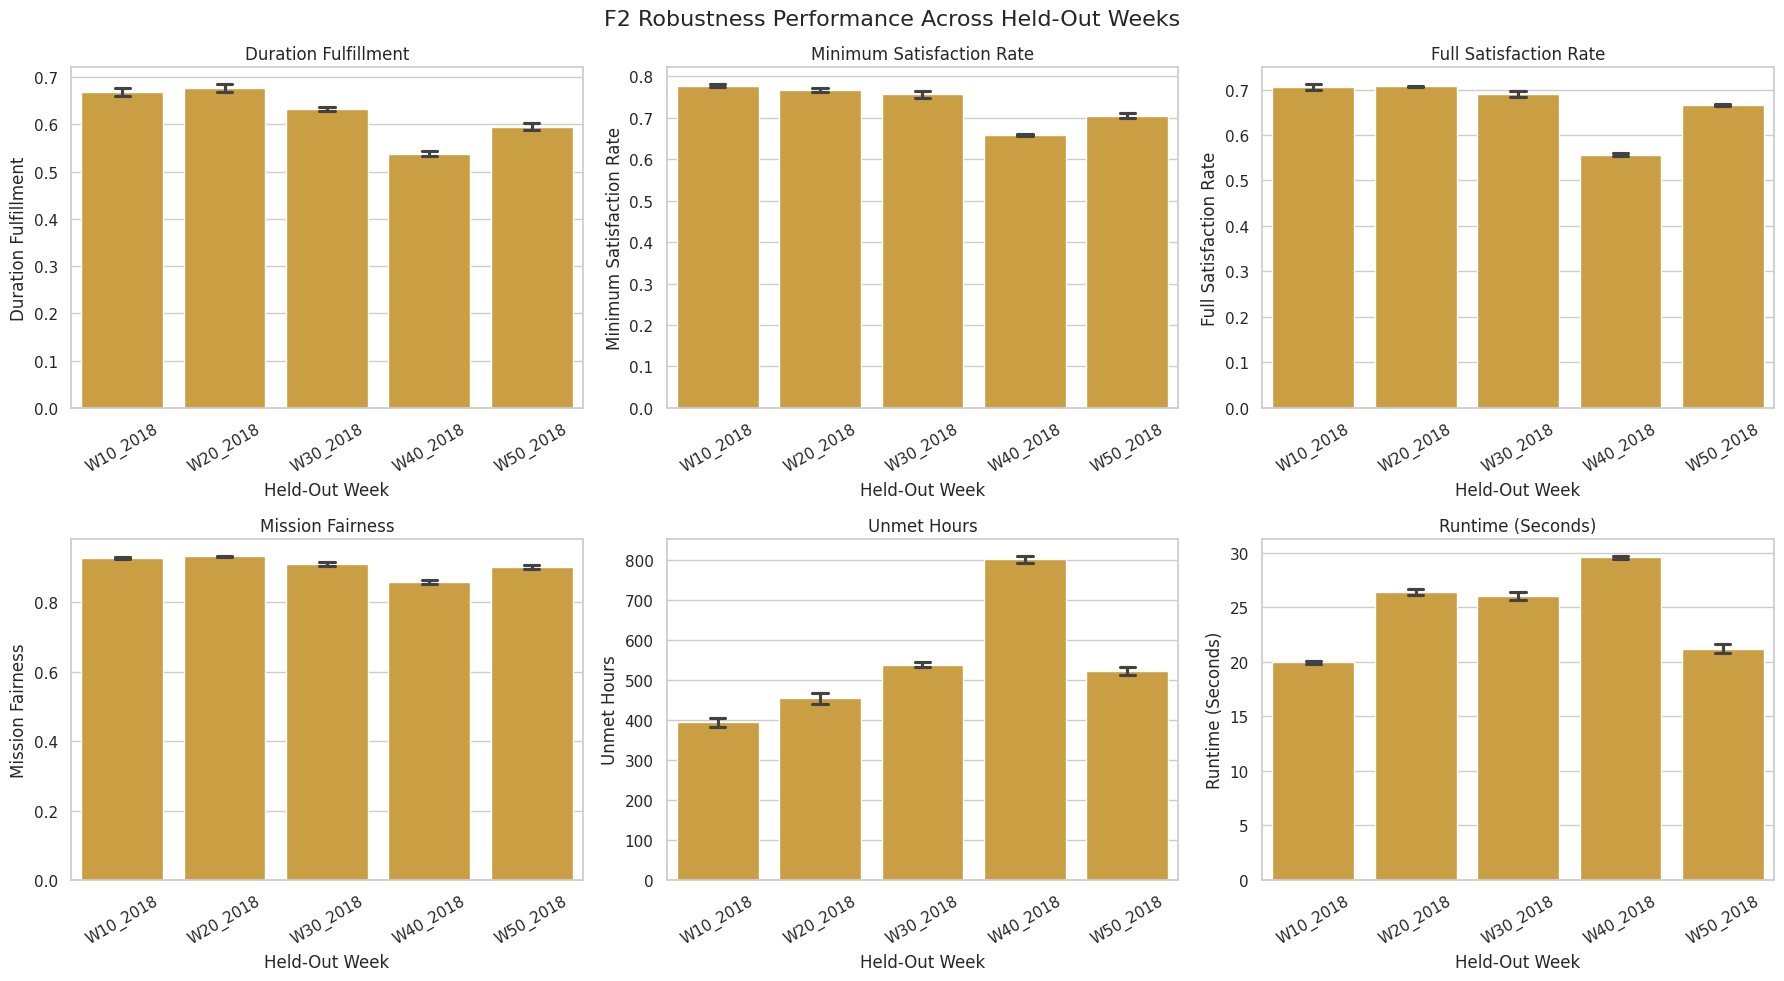

Figure saved to: /content/drive/MyDrive/BEE/shahad_fixed_bee_v2/results/f2_robustness_by_week.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plot_metrics = {
    "duration_fulfillment": "Duration Fulfillment",
    "minimum_satisfaction_rate": "Minimum Satisfaction Rate",
    "full_satisfaction_rate": "Full Satisfaction Rate",
    "mission_fairness": "Mission Fairness",
    "unmet_hours": "Unmet Hours",
    "runtime_seconds": "Runtime (Seconds)",
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (metric, title) in zip(axes.flat, plot_metrics.items()):
    sns.barplot(
        data=all_folds_summary,
        x="held_out_week",
        y=metric,
        errorbar="sd",
        capsize=0.15,
        color="#E0A72E",
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Held-Out Week")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=30)

plt.suptitle("F2 Robustness Performance Across Held-Out Weeks", fontsize=16)
plt.tight_layout()

figure_path = result_root / "f2_robustness_by_week.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path)

## Final Robustness Findings

The selected F2 configuration achieved an average duration fulfillment of 0.622, a minimum satisfaction rate of 0.733, a full satisfaction rate of 0.665, and mission fairness of 0.907 across the five held-out weeks. No constraint violations were recorded in any fold, confirming that all generated schedules remained feasible.

Performance was strongest on W10_2018 and W20_2018, while W40_2018 was the most challenging week, showing lower fulfillment and satisfaction rates and the highest number of unmet hours. The relatively small variation across the three training seeds within each fold indicates stable performance under different random initializations.

## Final Submission Packaging

This section organizes the trained models, generated schedules, figures, result files, and report materials into the final submission directory. It only packages the previously saved outputs and does not repeat any training or evaluation.

In [1]:
from pathlib import Path

final_output_root = Path("/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission")
final_figures_root = final_output_root / "fixed_bee_figures"
final_schedules_root = final_output_root / "fixed_bee_schedules"
final_models_root = final_output_root / "fixed_bee_models"

for folder in [
    final_output_root,
    final_figures_root,
    final_schedules_root,
    final_models_root,
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Final folders created:")
print(final_output_root)

Final folders created:
/content/drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission


In [7]:
from pathlib import Path

drive_root = Path("/content/google_drive/MyDrive")

wanted_names = [
    "all_folds_summary.csv",
    "final_robustness_summary.csv",
    "f2_robustness_by_week.png",
    "robustness_fold_5_summary.csv",
    "fixed_F2_fold_5_seed_456.zip",
]

for name in wanted_names:
    matches = list(drive_root.rglob(name))

    print(f"\n{name}:")
    if matches:
        for match in matches:
            print("✓", match)
    else:
        print("✗ Not found")


all_folds_summary.csv:
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/results/all_folds_summary.csv

final_robustness_summary.csv:
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/results/final_robustness_summary.csv

f2_robustness_by_week.png:
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/results/f2_robustness_by_week.png

robustness_fold_5_summary.csv:
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/results/robustness_fold_5_summary.csv

fixed_F2_fold_5_seed_456.zip:
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/models/fixed_F2_fold_5_seed_456.zip


In [8]:
from pathlib import Path

project_root = Path(
    "/content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2"
)

final_output_root = project_root / "final_submission"
final_figures_root = final_output_root / "fixed_bee_figures"
final_schedules_root = final_output_root / "fixed_bee_schedules"
final_models_root = final_output_root / "fixed_bee_models"

for folder in [
    final_output_root,
    final_figures_root,
    final_schedules_root,
    final_models_root,
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Correct final folder:")
print(final_output_root)

Correct final folder:
/content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission


In [9]:
import shutil

result_root = project_root / "results"
schedule_root = project_root / "schedules"
model_root = project_root / "models"

copied_files = []
missing_files = []

def copy_if_exists(source, destination):
    if source.exists():
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source, destination)
        copied_files.append(destination)
    else:
        missing_files.append(source)

for model_path in model_root.glob("fixed_F2_fold_*_seed_*.zip"):
    copy_if_exists(
        model_path,
        final_models_root / model_path.name,
    )

for schedule_path in schedule_root.glob(
    "robustness_fold_*_schedules.csv"
):
    copy_if_exists(
        schedule_path,
        final_schedules_root / schedule_path.name,
    )

copy_if_exists(
    result_root / "all_folds_summary.csv",
    final_output_root / "fixed_bee_cross_week_results.csv",
)

copy_if_exists(
    result_root / "final_robustness_summary.csv",
    final_output_root / "fixed_bee_cross_week_summary.csv",
)

copy_if_exists(
    result_root / "f2_robustness_by_week.png",
    final_figures_root / "f2_robustness_by_week.png",
)

print("Copied files:", len(copied_files))

for path in copied_files:
    print("✓", path)

if missing_files:
    print("\nMissing files:")
    for path in missing_files:
        print("✗", path)
else:
    print("\nAll requested files were copied successfully.")

Copied files: 23
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_models/fixed_F2_fold_1_seed_42.zip
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_models/fixed_F2_fold_1_seed_123.zip
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_models/fixed_F2_fold_1_seed_456.zip
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_models/fixed_F2_fold_2_seed_42.zip
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_models/fixed_F2_fold_2_seed_123.zip
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_models/fixed_F2_fold_2_seed_456.zip
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_models/fixed_F2_fold_3_seed_42.zip
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_models/fixed_F2_fold_3_seed_123.zip
✓ /content/google_drive/MyDrive/BE

In [10]:
from pathlib import Path

project_root = Path(
    "/content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2"
)

print("=== CSV FILES ===")
for path in sorted(project_root.rglob("*.csv")):
    if "final_submission" not in str(path):
        print(path.relative_to(project_root))

print("\n=== JSON FILES ===")
for path in sorted(project_root.rglob("*.json")):
    if "final_submission" not in str(path):
        print(path.relative_to(project_root))

print("\n=== NOTEBOOK FILES ===")
for path in sorted(project_root.rglob("*.ipynb")):
    print(path.relative_to(project_root))

=== CSV FILES ===
logs/F1/seed_42/monitor_target_1000.csv.monitor.csv
logs/F1/seed_42/monitor_target_10000.csv.monitor.csv
logs/F1/seed_42/monitor_target_5000.csv.monitor.csv
logs/F2/seed_123/monitor_target_25000.csv.monitor.csv
logs/F2/seed_42/monitor_target_1000.csv.monitor.csv
logs/F2/seed_42/monitor_target_10000.csv.monitor.csv
logs/F2/seed_42/monitor_target_25000.csv.monitor.csv
logs/F2/seed_42/monitor_target_5000.csv.monitor.csv
logs/F2/seed_456/monitor_target_25000.csv.monitor.csv
logs/F3/seed_42/monitor_target_1000.csv.monitor.csv
logs/F3/seed_42/monitor_target_5000.csv.monitor.csv
logs/F4/seed_42/monitor_target_1000.csv.monitor.csv
logs/F5/seed_42/monitor_target_1000.csv.monitor.csv
logs/robustness/fold_1/seed_123/monitor.csv
logs/robustness/fold_1/seed_42/monitor.csv
logs/robustness/fold_1/seed_456/monitor.csv
logs/robustness/fold_2/seed_123/monitor.csv
logs/robustness/fold_2/seed_42/monitor.csv
logs/robustness/fold_2/seed_456/monitor.csv
logs/robustness/fold_3/seed_123/monit

In [11]:
import json
import re
from pathlib import Path

import pandas as pd
import numpy as np

project_root = Path(
    "/content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2"
)

result_root = project_root / "results"
final_output_root = project_root / "final_submission"


def clean_value(value):
    if pd.isna(value):
        return None
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    return value


# 1. Configuration-search results
ranking_files = sorted(
    result_root.glob("stage_*_configuration_ranking.csv")
)

configuration_frames = []

for path in ranking_files:
    frame = pd.read_csv(path)

    stage_match = re.search(r"stage_(\d+)", path.name)
    frame["training_stage_timesteps"] = (
        int(stage_match.group(1)) if stage_match else None
    )
    frame["source_file"] = path.name
    configuration_frames.append(frame)

configuration_search = pd.concat(
    configuration_frames,
    ignore_index=True,
)

configuration_search_path = (
    final_output_root / "fixed_bee_configuration_search.csv"
)

configuration_search.to_csv(
    configuration_search_path,
    index=False,
)


# 2. Validation results
validation_files = sorted(
    result_root.glob("stage_*_validation_results.csv")
)

validation_frames = []

for path in validation_files:
    frame = pd.read_csv(path)

    stage_match = re.search(r"stage_(\d+)", path.name)
    frame["training_stage_timesteps"] = (
        int(stage_match.group(1)) if stage_match else None
    )
    frame["source_file"] = path.name
    validation_frames.append(frame)

validation_results = pd.concat(
    validation_frames,
    ignore_index=True,
)

validation_results_path = (
    final_output_root / "fixed_bee_validation_results.csv"
)

validation_results.to_csv(
    validation_results_path,
    index=False,
)


# 3. Training-run logs
monitor_files = sorted(
    project_root.glob("logs/**/monitor.csv")
)

training_frames = []

for path in monitor_files:
    try:
        frame = pd.read_csv(path, comment="#")

        relative_path = str(path.relative_to(project_root))
        frame["run_source"] = relative_path

        fold_match = re.search(r"fold_(\d+)", relative_path)
        seed_match = re.search(r"seed_(\d+)", relative_path)

        frame["fold"] = (
            int(fold_match.group(1)) if fold_match else None
        )
        frame["training_seed"] = (
            int(seed_match.group(1)) if seed_match else None
        )

        training_frames.append(frame)

    except Exception as error:
        print("Skipped:", path, error)

training_runs = pd.concat(
    training_frames,
    ignore_index=True,
)

training_runs_path = (
    final_output_root / "fixed_bee_training_runs.csv"
)

training_runs.to_csv(
    training_runs_path,
    index=False,
)


# 4. Selected F2 threshold results
configuration_column = next(
    (
        column
        for column in configuration_search.columns
        if column.lower() in [
            "configuration",
            "configuration_id",
            "config",
            "config_id",
        ]
    ),
    None,
)

if configuration_column is not None:
    threshold_results = configuration_search[
        configuration_search[configuration_column]
        .astype(str)
        .str.upper()
        .eq("F2")
    ].copy()
else:
    threshold_results = configuration_search.copy()

threshold_results_path = (
    final_output_root / "fixed_bee_threshold_results.csv"
)

threshold_results.to_csv(
    threshold_results_path,
    index=False,
)


# 5. Final selected configuration JSON
if len(threshold_results) > 0:
    selected_row = threshold_results.iloc[-1]
else:
    selected_row = configuration_search.iloc[-1]

selected_configuration = {
    "selected_configuration": "F2",
    "method": "fixed-threshold bee-inspired scheduling",
    "selection_basis": (
        "validation performance followed by five-fold "
        "cross-week robustness evaluation"
    ),
    "training_seeds": [42, 123, 456],
    "evaluation_seeds": [1001, 2002, 3003, 4004, 5005],
    "training_timesteps_per_run": 25000,
    "constraint_violations_observed": 0,
    "selected_result_row": {
        key: clean_value(value)
        for key, value in selected_row.to_dict().items()
    },
}

configuration_json_path = (
    final_output_root / "fixed_bee_configuration.json"
)

with open(configuration_json_path, "w", encoding="utf-8") as file:
    json.dump(
        selected_configuration,
        file,
        indent=2,
        ensure_ascii=False,
    )


created_files = [
    configuration_search_path,
    training_runs_path,
    validation_results_path,
    threshold_results_path,
    configuration_json_path,
]

print("Created files:", len(created_files))

for path in created_files:
    print("✓", path)

print("\nRows:")
print("Configuration search:", len(configuration_search))
print("Training runs:", len(training_runs))
print("Validation results:", len(validation_results))
print("Threshold results:", len(threshold_results))

Created files: 5
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_configuration_search.csv
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_training_runs.csv
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_validation_results.csv
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_threshold_results.csv
✓ /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_configuration.json

Rows:
Configuration search: 10
Training runs: 1764
Validation results: 50
Threshold results: 3


## Fixed-Threshold BEE Report Export

This section generates the final report section from the completed configuration search, validation, and cross-week robustness results. No additional training or evaluation is performed.

In [15]:
from pathlib import Path
import pandas as pd

project_root = Path(
    "/content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2"
)

result_root = project_root / "results"
final_output_root = project_root / "final_submission"

summary_path = result_root / "final_robustness_summary.csv"
all_folds_path = result_root / "all_folds_summary.csv"

summary = pd.read_csv(summary_path)
all_folds = pd.read_csv(all_folds_path)

metric_lookup = summary.set_index("metric")


def metric_value(metric, column):
    return float(metric_lookup.loc[metric, column])


duration_mean = metric_value("duration_fulfillment", "mean")
duration_std = metric_value("duration_fulfillment", "std")

minimum_mean = metric_value("minimum_satisfaction_rate", "mean")
minimum_std = metric_value("minimum_satisfaction_rate", "std")

full_mean = metric_value("full_satisfaction_rate", "mean")
full_std = metric_value("full_satisfaction_rate", "std")

unmet_mean = metric_value("unmet_hours", "mean")
unmet_std = metric_value("unmet_hours", "std")

fairness_mean = metric_value("mission_fairness", "mean")
fairness_std = metric_value("mission_fairness", "std")

violations_mean = metric_value("constraint_violations", "mean")

runtime_mean = metric_value("runtime_seconds", "mean")
runtime_std = metric_value("runtime_seconds", "std")

week_summary = (
    all_folds
    .groupby("held_out_week", as_index=False)
    .agg(
        duration_fulfillment=("duration_fulfillment", "mean"),
        minimum_satisfaction_rate=("minimum_satisfaction_rate", "mean"),
        full_satisfaction_rate=("full_satisfaction_rate", "mean"),
        unmet_hours=("unmet_hours", "mean"),
        mission_fairness=("mission_fairness", "mean"),
        constraint_violations=("constraint_violations", "sum"),
    )
)

best_week = week_summary.loc[
    week_summary["duration_fulfillment"].idxmax(),
    "held_out_week",
]

hardest_week = week_summary.loc[
    week_summary["duration_fulfillment"].idxmin(),
    "held_out_week",
]

report = f"""# Fixed-Threshold BEE Scheduler

## Method

The fixed-threshold BEE scheduler combines a bee-inspired eligibility
mechanism with a Maskable Proximal Policy Optimization policy. Candidate
communication requests are scored using priority, urgency, duration, and
visibility-related information. Only eligible requests are presented to
the reinforcement-learning policy, while action masking prevents invalid
scheduling decisions.

Five fixed-threshold configurations were examined through staged training
and validation. Configuration F2 was selected based on its validation
performance and was subsequently evaluated using a five-fold cross-week
robustness protocol.

## Experimental Protocol

The experiments used the five SatNet weeks W10_2018, W20_2018, W30_2018,
W40_2018, and W50_2018. In every robustness fold, one week was held out
for testing while the remaining four weeks were used for training.

For each fold, three independent models were trained using seeds 42, 123,
and 456. Each model was trained for 25,000 timesteps and evaluated using
five shared evaluation seeds: 1001, 2002, 3003, 4004, and 5005. This
produced 75 robustness evaluations across the five held-out weeks.

## Final Robustness Results

Across all folds and training seeds, F2 achieved:

- Duration fulfillment: {duration_mean:.3f} ± {duration_std:.3f}
- Minimum satisfaction rate: {minimum_mean:.3f} ± {minimum_std:.3f}
- Full satisfaction rate: {full_mean:.3f} ± {full_std:.3f}
- Unmet hours: {unmet_mean:.3f} ± {unmet_std:.3f}
- Mission fairness: {fairness_mean:.3f} ± {fairness_std:.3f}
- Constraint violations: {violations_mean:.0f}
- Mean evaluation runtime: {runtime_mean:.3f} ± {runtime_std:.3f} seconds

No constraint violations were recorded during the robustness evaluation,
confirming that the generated schedules remained feasible.

## Cross-Week Findings

The strongest duration-fulfillment performance was observed on
{best_week}, while {hardest_week} was the most challenging held-out week.
Performance differences between weeks indicate that scheduling difficulty
depends on the demand, visibility, and contention characteristics of each
week.

The relatively small variation between the three independently trained
seeds indicates that the selected F2 configuration is stable under
different random initializations.

## Conclusion

The evaluation demonstrates that the selected fixed-threshold BEE
configuration generalizes across unseen scheduling weeks while maintaining
constraint-safe behavior. The approach provides stable mission fairness
and satisfaction performance, although the variation in unmet hours shows
that highly congested weeks remain more difficult to schedule.

The final models, schedules, configuration-search results, validation
results, robustness summaries, and figures are included with the
submission artifacts.
"""

report_path = (
    final_output_root / "fixed_bee_report_section.md"
)

report_path.write_text(report, encoding="utf-8")

print("✓ Report created:")
print(report_path)


✓ Report created:
/content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_report_section.md


In [14]:
import shutil
from pathlib import Path

drive_root = Path("/content/google_drive/MyDrive")

final_output_root = Path(
    "/content/google_drive/MyDrive/BEE/"
    "shahad_fixed_bee_v2/final_submission"
)

notebook_matches = [
    path
    for path in drive_root.rglob("03_fixed_threshold_bee*.ipynb")
    if "final_submission" not in str(path)
]

if notebook_matches:
    source_notebook = max(
        notebook_matches,
        key=lambda path: path.stat().st_mtime,
    )

    destination_notebook = (
        final_output_root / "03_fixed_threshold_bee.ipynb"
    )

    shutil.copy2(
        source_notebook,
        destination_notebook,
    )

    print("✓ Notebook copied from:")
    print(source_notebook)
    print("✓ Notebook copied to:")
    print(destination_notebook)

else:
    print("✗ Notebook was not found in MyDrive")


required_items = [
    "03_fixed_threshold_bee.ipynb",
    "fixed_bee_models",
    "fixed_bee_configuration_search.csv",
    "fixed_bee_training_runs.csv",
    "fixed_bee_validation_results.csv",
    "fixed_bee_cross_week_results.csv",
    "fixed_bee_cross_week_summary.csv",
    "fixed_bee_threshold_results.csv",
    "fixed_bee_schedules",
    "fixed_bee_configuration.json",
    "fixed_bee_figures",
    "fixed_bee_report_section.md",
]

print("\nFINAL SUBMISSION CHECK ")

missing_items = []

for item in required_items:
    path = final_output_root / item

    if path.exists():
        print("✓", item)
    else:
        print("✗", item)
        missing_items.append(item)

if not missing_items:
    print("\n✓ All required submission items are present.")
else:
    print("\nMissing items:", missing_items)

✓ Notebook copied from:
/content/google_drive/MyDrive/Colab Notebooks/03_fixed_threshold_bee.ipynb
✓ Notebook copied to:
/content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/03_fixed_threshold_bee.ipynb

FINAL SUBMISSION CHECK 
✓ 03_fixed_threshold_bee.ipynb
✓ fixed_bee_models
✓ fixed_bee_configuration_search.csv
✓ fixed_bee_training_runs.csv
✓ fixed_bee_validation_results.csv
✓ fixed_bee_cross_week_results.csv
✓ fixed_bee_cross_week_summary.csv
✓ fixed_bee_threshold_results.csv
✓ fixed_bee_schedules
✓ fixed_bee_configuration.json
✓ fixed_bee_figures
✓ fixed_bee_report_section.md

✓ All required submission items are present.


In [19]:
from pathlib import Path

plain_ppo_root = Path(
    "/content/google_drive/MyDrive/BEE/"
    "shahad_fixed_bee_v2/member2_plain_ppo"
)

print("Plain PPO directory exists:", plain_ppo_root.exists())

print("\nPlain PPO CSV Files")
for path in sorted(plain_ppo_root.rglob("*.csv")):
    print(path.relative_to(plain_ppo_root))

print("\n Plain PPO Configuration Files")
for path in sorted(plain_ppo_root.rglob("*.json")):
    print(path.relative_to(plain_ppo_root))

Plain PPO directory exists: True

Plain PPO CSV Files
plain_ppo_cross_week_results.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_1_W10_2018_seed_1001.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_1_W10_2018_seed_2002.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_1_W10_2018_seed_3003.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_1_W10_2018_seed_4004.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_1_W10_2018_seed_5005.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_2_W20_2018_seed_1001.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_2_W20_2018_seed_2002.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_2_W20_2018_seed_3003.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_2_W20_2018_seed_4004.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_2_W20_2018_seed_5005.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_3_W30_2018_seed_1001.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_3_W30_2018_seed_2002.csv
plain_ppo_cross_week_schedules/plain_ppo_fold_3_W30_2018_seed

## Plain PPO Baseline Results

The Plain PPO baseline outputs are loaded from the shared project directory. The cross-week results and summary files are inspected to verify their structure and identify the common evaluation metrics required for comparison with the selected Fixed-Threshold BEE configuration (F2). No additional training or evaluation is performed in this step.

In [20]:
import pandas as pd

plain_ppo_results_path = (
    plain_ppo_root / "plain_ppo_cross_week_results.csv"
)

plain_ppo_summary_path = (
    plain_ppo_root / "plain_ppo_cross_week_summary.csv"
)

plain_ppo_results = pd.read_csv(plain_ppo_results_path)
plain_ppo_summary = pd.read_csv(plain_ppo_summary_path)

print("Cross-week results shape:", plain_ppo_results.shape)
print("Cross-week results columns:")
print(plain_ppo_results.columns.tolist())

display(plain_ppo_results.head())

print("\nCross-week summary shape:", plain_ppo_summary.shape)
print("Cross-week summary columns:")
print(plain_ppo_summary.columns.tolist())

display(plain_ppo_summary)

Cross-week results shape: (25, 18)
Cross-week results columns:
['week_key', 'number_of_requests', 'scheduled_requests', 'allocated_hours', 'duration_fulfillment', 'minimum_satisfaction_rate', 'full_satisfaction_rate', 'unmet_hours', 'mission_fairness', 'constraint_violations', 'method', 'seed', 'episode_reward', 'steps', 'runtime_seconds', 'fold', 'held_out_week', 'training_seed']


,week_key,number_of_requests,scheduled_requests,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,method,seed,episode_reward,steps,runtime_seconds,fold,held_out_week,training_seed
0,W10_2018,257,196,753.602500,0.632482,0.762646,0.700389,437.897500,0.918465,0,plain_maskable_ppo,1001,292.413090,196,15.286368,1,W10_2018,42
1,W10_2018,257,201,805.586389,0.676111,0.782101,0.708171,385.913611,0.936896,0,plain_maskable_ppo,2002,299.977479,201,15.096028,1,W10_2018,42
2,W10_2018,257,199,783.675278,0.657722,0.774319,0.696498,407.824722,0.930591,0,plain_maskable_ppo,3003,296.638978,199,14.799622,1,W10_2018,42
3,W10_2018,257,195,766.238056,0.643087,0.758755,0.700389,425.261944,0.914064,0,plain_maskable_ppo,4004,291.167257,195,14.865719,1,W10_2018,42
4,W10_2018,257,198,796.560278,0.668536,0.770428,0.712062,394.939722,0.928049,0,plain_maskable_ppo,5005,295.798215,198,15.656799,1,W10_2018,42



Cross-week summary shape: (5, 9)
Cross-week summary columns:
['fold', 'held_out_week', 'mean_duration_fulfillment', 'std_duration_fulfillment', 'mean_minimum_satisfaction', 'mean_full_satisfaction', 'mean_mission_fairness', 'mean_runtime_seconds', 'total_constraint_violations']


,fold,held_out_week,mean_duration_fulfillment,std_duration_fulfillment,mean_minimum_satisfaction,mean_full_satisfaction,mean_mission_fairness,mean_runtime_seconds,total_constraint_violations
0,1,W10_2018,0.655587,0.017913,0.769650,0.703502,0.925613,15.140907,0
1,2,W20_2018,0.680360,0.015392,0.765986,0.702041,0.926599,23.986377,0
2,3,W30_2018,0.644111,0.014843,0.764505,0.694881,0.917371,20.249704,0
3,4,W40_2018,0.528073,0.010019,0.657658,0.549550,0.865687,22.495197,0
4,5,W50_2018,0.592003,0.017830,0.708364,0.670545,0.901552,17.197741,0


In [21]:
fixed_bee_results_path = (
    final_output_root / "fixed_bee_cross_week_results.csv"
)

fixed_bee_results = pd.read_csv(fixed_bee_results_path)

print("Fixed-Threshold BEE results shape:", fixed_bee_results.shape)
print("Fixed-Threshold BEE results columns:")
print(fixed_bee_results.columns.tolist())

display(fixed_bee_results)

Fixed-Threshold BEE results shape: (15, 10)
Fixed-Threshold BEE results columns:
['training_seed', 'duration_fulfillment', 'minimum_satisfaction_rate', 'full_satisfaction_rate', 'unmet_hours', 'mission_fairness', 'constraint_violations', 'runtime_seconds', 'fold', 'held_out_week']


,training_seed,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,runtime_seconds,fold,held_out_week
0,42,0.675381,0.782101,0.711284,386.784111,0.931901,0,20.092544,1,W10_2018
1,123,0.658316,0.772763,0.698054,407.116611,0.926401,0,19.951188,1,W10_2018
2,456,0.672522,0.778988,0.708949,390.189667,0.927093,0,19.863123,1,W10_2018
3,42,0.681762,0.768707,0.706803,447.602056,0.933604,0,26.312101,2,W20_2018
4,123,0.682952,0.771429,0.706122,445.928167,0.934688,0,26.751661,2,W20_2018
5,456,0.666165,0.762585,0.707483,469.538833,0.930637,0,26.235579,2,W20_2018
6,42,0.627950,0.747440,0.681911,544.681778,0.909428,0,25.662275,3,W30_2018
7,123,0.632848,0.761775,0.692833,537.510444,0.906316,0,26.214893,3,W30_2018
8,456,0.635571,0.759727,0.694198,533.523833,0.915738,0,26.266739,3,W30_2018
9,42,0.532713,0.660661,0.558559,811.537611,0.852731,0,29.685654,4,W40_2018


## Fixed-Threshold BEE vs. Plain PPO Comparison

The selected Fixed-Threshold BEE configuration (F2) is compared with the Plain PPO baseline across the five held-out weeks. The comparison uses the shared scheduling-quality, feasibility, and runtime metrics. Weekly means are calculated first to ensure that both approaches are compared consistently despite using different numbers of experimental seeds.

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

comparison_metrics = [
    "duration_fulfillment",
    "minimum_satisfaction_rate",
    "full_satisfaction_rate",
    "unmet_hours",
    "mission_fairness",
    "constraint_violations",
    "runtime_seconds",
]

# Calculate weekly means for Fixed-Threshold BEE.
fixed_weekly = (
    fixed_bee_results
    .groupby("held_out_week", as_index=False)[comparison_metrics]
    .mean()
    .rename(columns={"held_out_week": "week_key"})
)

# Calculate weekly means for Plain PPO.
plain_weekly = (
    plain_ppo_results
    .groupby("week_key", as_index=False)[comparison_metrics]
    .mean()
)

# Create the cross-week comparison table.
weekly_comparison = fixed_weekly.merge(
    plain_weekly,
    on="week_key",
    suffixes=("_fixed_bee", "_plain_ppo"),
)

for metric in comparison_metrics:
    weekly_comparison[f"{metric}_difference"] = (
        weekly_comparison[f"{metric}_fixed_bee"]
        - weekly_comparison[f"{metric}_plain_ppo"]
    )

# Create the overall comparison summary.
summary_rows = []

higher_is_better = {
    "duration_fulfillment": True,
    "minimum_satisfaction_rate": True,
    "full_satisfaction_rate": True,
    "unmet_hours": False,
    "mission_fairness": True,
    "constraint_violations": False,
    "runtime_seconds": False,
}

for metric in comparison_metrics:
    fixed_mean = weekly_comparison[f"{metric}_fixed_bee"].mean()
    plain_mean = weekly_comparison[f"{metric}_plain_ppo"].mean()
    difference = fixed_mean - plain_mean

    if np.isclose(fixed_mean, plain_mean):
        preferred_model = "Tie"
    elif higher_is_better[metric]:
        preferred_model = (
            "Fixed-Threshold BEE"
            if fixed_mean > plain_mean
            else "Plain PPO"
        )
    else:
        preferred_model = (
            "Fixed-Threshold BEE"
            if fixed_mean < plain_mean
            else "Plain PPO"
        )

    summary_rows.append({
        "metric": metric,
        "fixed_bee_mean": fixed_mean,
        "plain_ppo_mean": plain_mean,
        "difference": difference,
        "preferred_model": preferred_model,
    })

overall_comparison = pd.DataFrame(summary_rows)

# Save the comparison tables.
weekly_comparison_path = (
    final_output_root
    / "fixed_bee_vs_plain_ppo_by_week.csv"
)

overall_comparison_path = (
    final_output_root
    / "fixed_bee_vs_plain_ppo_summary.csv"
)

weekly_comparison.to_csv(
    weekly_comparison_path,
    index=False,
)

overall_comparison.to_csv(
    overall_comparison_path,
    index=False,
)

print("Weekly comparison:")
display(weekly_comparison.round(6))

print("\nOverall comparison:")
display(overall_comparison.round(6))

print("\nWeekly comparison saved to:", weekly_comparison_path)
print("Overall comparison saved to:", overall_comparison_path)

Weekly comparison:


,week_key,duration_fulfillment_fixed_bee,minimum_satisfaction_rate_fixed_bee,full_satisfaction_rate_fixed_bee,unmet_hours_fixed_bee,mission_fairness_fixed_bee,constraint_violations_fixed_bee,runtime_seconds_fixed_bee,duration_fulfillment_plain_ppo,minimum_satisfaction_rate_plain_ppo,...,mission_fairness_plain_ppo,constraint_violations_plain_ppo,runtime_seconds_plain_ppo,duration_fulfillment_difference,minimum_satisfaction_rate_difference,full_satisfaction_rate_difference,unmet_hours_difference,mission_fairness_difference,constraint_violations_difference,runtime_seconds_difference
0,W10_2018,0.668740,0.777951,0.706096,394.696796,0.928465,0.0,19.968952,0.655587,0.769650,...,0.925613,0.0,15.140907,0.013152,0.008301,0.002594,-15.670704,0.002852,0.0,4.828044
1,W20_2018,0.676960,0.767574,0.706803,454.356352,0.932976,0.0,26.433114,0.680360,0.765986,...,0.926599,0.0,23.986377,-0.003400,0.001587,0.004762,4.782185,0.006378,0.0,2.446736
2,W30_2018,0.632123,0.756314,0.689647,538.572019,0.910494,0.0,26.047969,0.644111,0.764505,...,0.917371,0.0,20.249704,-0.011988,-0.008191,-0.005233,17.550630,-0.006877,0.0,5.798265
3,W40_2018,0.537885,0.658659,0.556557,802.555944,0.858275,0.0,29.594677,0.528073,0.657658,...,0.865687,0.0,22.495197,0.009811,0.001001,0.007007,-17.039278,-0.007412,0.0,7.099480
4,W50_2018,0.595063,0.705455,0.666424,523.258963,0.902767,0.0,21.219559,0.592003,0.708364,...,0.901552,0.0,17.197741,0.003060,-0.002909,-0.004121,-3.954481,0.001215,0.0,4.021818



Overall comparison:


,metric,fixed_bee_mean,plain_ppo_mean,difference,preferred_model
0,duration_fulfillment,0.622154,0.620027,0.002127,Fixed-Threshold BEE
1,minimum_satisfaction_rate,0.733190,0.733233,-0.000042,Plain PPO
2,full_satisfaction_rate,0.665105,0.664104,0.001002,Fixed-Threshold BEE
3,unmet_hours,542.688015,545.554344,-2.866330,Fixed-Threshold BEE
4,mission_fairness,0.906596,0.907364,-0.000769,Plain PPO
5,constraint_violations,0.000000,0.000000,0.000000,Tie
6,runtime_seconds,24.652854,19.813985,4.838869,Plain PPO



Weekly comparison saved to: /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_vs_plain_ppo_by_week.csv
Overall comparison saved to: /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_vs_plain_ppo_summary.csv


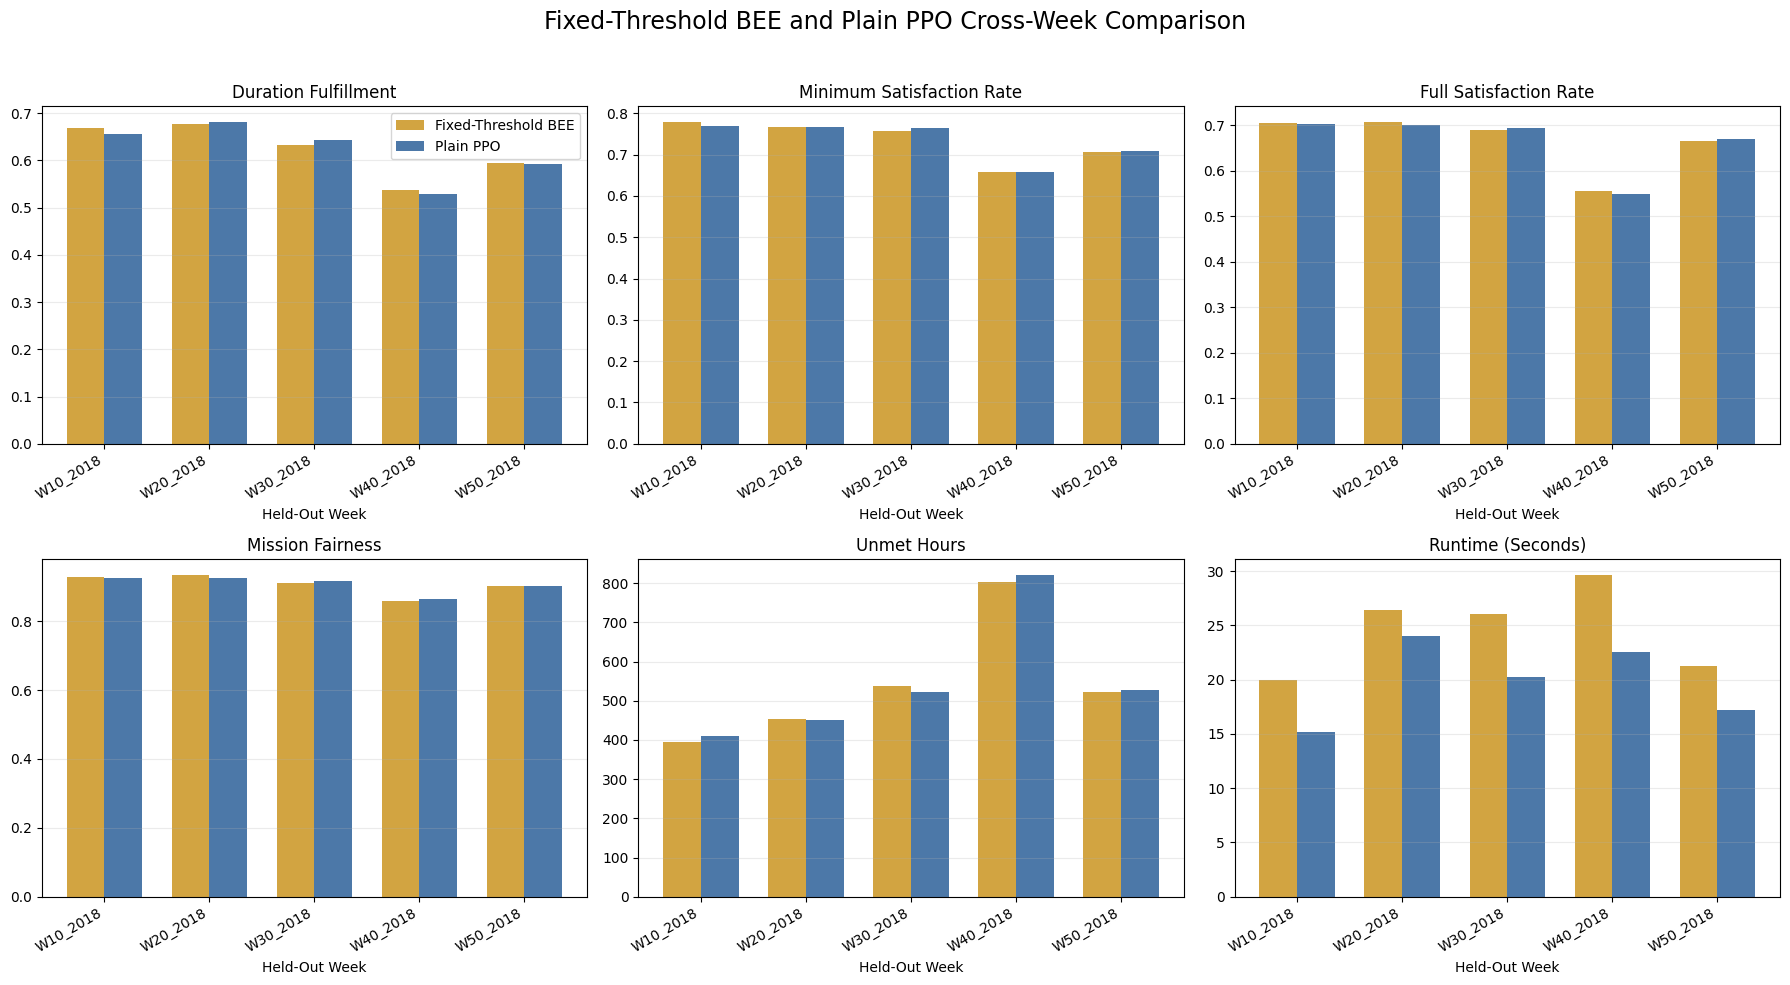

Comparison figure saved to: /content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_figures/fixed_bee_vs_plain_ppo.png


In [23]:
plot_metrics = [
    ("duration_fulfillment", "Duration Fulfillment"),
    ("minimum_satisfaction_rate", "Minimum Satisfaction Rate"),
    ("full_satisfaction_rate", "Full Satisfaction Rate"),
    ("mission_fairness", "Mission Fairness"),
    ("unmet_hours", "Unmet Hours"),
    ("runtime_seconds", "Runtime (Seconds)"),
]

weeks = weekly_comparison["week_key"].tolist()
x = np.arange(len(weeks))
bar_width = 0.36

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 10),
)

axes = axes.flatten()

for axis, (metric, title) in zip(axes, plot_metrics):
    fixed_values = weekly_comparison[
        f"{metric}_fixed_bee"
    ]

    plain_values = weekly_comparison[
        f"{metric}_plain_ppo"
    ]

    axis.bar(
        x - bar_width / 2,
        fixed_values,
        bar_width,
        label="Fixed-Threshold BEE",
        color="#D2A441",
    )

    axis.bar(
        x + bar_width / 2,
        plain_values,
        bar_width,
        label="Plain PPO",
        color="#4C78A8",
    )

    axis.set_title(title)
    axis.set_xticks(x)
    axis.set_xticklabels(
        weeks,
        rotation=30,
        ha="right",
    )
    axis.set_xlabel("Held-Out Week")
    axis.grid(
        axis="y",
        alpha=0.25,
    )

axes[0].legend()

fig.suptitle(
    "Fixed-Threshold BEE and Plain PPO Cross-Week Comparison",
    fontsize=17,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

comparison_figure_path = (
    final_figures_root
    / "fixed_bee_vs_plain_ppo.png"
)

plt.savefig(
    comparison_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Comparison figure saved to:", comparison_figure_path)

In [24]:
report_path = (
    final_output_root
    / "fixed_bee_report_section.md"
)

report_text = report_path.read_text(
    encoding="utf-8"
)

comparison_section = """
## Comparison with Plain PPO

The selected Fixed-Threshold BEE configuration (F2) was compared with the Plain PPO baseline across the five held-out weeks. Both approaches produced highly similar scheduling-quality results. Fixed-Threshold BEE achieved a slightly higher mean duration fulfillment (0.6222 versus 0.6200) and full satisfaction rate (0.6651 versus 0.6641). It also reduced the mean unmet demand from 545.55 hours to 542.69 hours.

Plain PPO achieved marginally higher minimum satisfaction (0.7332 versus 0.7332 after rounding) and mission fairness (0.9074 versus 0.9066). These differences were very small and did not indicate a substantial scheduling-quality advantage for either approach. Both methods recorded zero constraint violations across all evaluated weeks, confirming that all generated schedules remained feasible.

The main difference was computational runtime. Plain PPO required an average of 19.81 seconds per evaluation, compared with 24.65 seconds for Fixed-Threshold BEE. Therefore, the bee-inspired eligibility mechanism introduced additional computational overhead while maintaining scheduling performance comparable to the unfiltered PPO baseline.

Overall, Fixed-Threshold BEE preserved the baseline policy's scheduling quality and feasibility while introducing an interpretable bio-inspired request-eligibility mechanism. However, the results do not demonstrate a large overall performance improvement over Plain PPO, and the added mechanism increases evaluation runtime.

"""

comparison_heading = "## Comparison with Plain PPO"
conclusion_heading = "## Conclusion"

if comparison_heading in report_text:
    before_comparison = report_text.split(
        comparison_heading,
        1,
    )[0]

    if conclusion_heading in report_text:
        conclusion_text = (
            conclusion_heading
            + report_text.split(
                conclusion_heading,
                1,
            )[1]
        )
    else:
        conclusion_text = ""

    updated_report = (
        before_comparison
        + comparison_section
        + conclusion_text
    )

elif conclusion_heading in report_text:
    updated_report = report_text.replace(
        conclusion_heading,
        comparison_section + conclusion_heading,
        1,
    )

else:
    updated_report = (
        report_text
        + "\n"
        + comparison_section
    )

report_path.write_text(
    updated_report,
    encoding="utf-8",
)

print("Report updated successfully:")
print(report_path)



Report updated successfully:
/content/google_drive/MyDrive/BEE/shahad_fixed_bee_v2/final_submission/fixed_bee_report_section.md


## Final Submission Package Verification

The final Fixed-Threshold BEE submission package is assembled and verified in this step. The check confirms the availability of the notebook, trained models, generated schedules, configuration records, experimental results, comparison tables, figures, and report section. This verification does not repeat any training or evaluation; it only validates that all required output artifacts were saved successfully.

In [25]:
from pathlib import Path
import shutil

notebook_source = Path(
    "/content/google_drive/MyDrive/Colab Notebooks/"
    "03_fixed_threshold_bee.ipynb"
)

notebook_destination = (
    final_output_root
    / "03_fixed_threshold_bee.ipynb"
)

shutil.copy2(
    notebook_source,
    notebook_destination,
)

required_items = [
    "03_fixed_threshold_bee.ipynb",
    "fixed_bee_models",
    "fixed_bee_schedules",
    "fixed_bee_configuration_search.csv",
    "fixed_bee_training_runs.csv",
    "fixed_bee_validation_results.csv",
    "fixed_bee_cross_week_results.csv",
    "fixed_bee_cross_week_summary.csv",
    "fixed_bee_threshold_results.csv",
    "fixed_bee_configuration.json",
    "fixed_bee_figures",
    "fixed_bee_report_section.md",
    "fixed_bee_vs_plain_ppo_by_week.csv",
    "fixed_bee_vs_plain_ppo_summary.csv",
]

missing_items = []

print("=== FINAL SUBMISSION CHECK ===")

for item in required_items:
    path = final_output_root / item

    if path.exists():
        print("✓", item)
    else:
        print("✗", item)
        missing_items.append(item)

comparison_figure = (
    final_figures_root
    / "fixed_bee_vs_plain_ppo.png"
)

if comparison_figure.exists():
    print("✓ fixed_bee_figures/fixed_bee_vs_plain_ppo.png")
else:
    print("✗ fixed_bee_figures/fixed_bee_vs_plain_ppo.png")
    missing_items.append(
        "fixed_bee_figures/fixed_bee_vs_plain_ppo.png"
    )

if not missing_items:
    print("\n✓ Final submission package is complete.")
else:
    print("\nMissing items:", missing_items)

=== FINAL SUBMISSION CHECK ===
✓ 03_fixed_threshold_bee.ipynb
✓ fixed_bee_models
✓ fixed_bee_schedules
✓ fixed_bee_configuration_search.csv
✓ fixed_bee_training_runs.csv
✓ fixed_bee_validation_results.csv
✓ fixed_bee_cross_week_results.csv
✓ fixed_bee_cross_week_summary.csv
✓ fixed_bee_threshold_results.csv
✓ fixed_bee_configuration.json
✓ fixed_bee_figures
✓ fixed_bee_report_section.md
✓ fixed_bee_vs_plain_ppo_by_week.csv
✓ fixed_bee_vs_plain_ppo_summary.csv
✓ fixed_bee_figures/fixed_bee_vs_plain_ppo.png

✓ Final submission package is complete.
